# ¿Cuántos mosquitos traeríamos tras cuatro noches en Cheté?

**Juan Montoya y Laura Ostos.** Imaginamos cuatro frascos pasivos por noche, unas ocho horas mientras dormíamos y dos noches en cada sector: población y cercanía a la mina. En población propusimos observar interior y exterior. ¿Importarían el lugar, el señuelo y el contraste de colores? ¿Tendría sentido ir en noviembre o diciembre, de noche? ¿Qué especies encontraríamos?

Nuestra [Fermi original](../EstimacionFermi_00/estimacion_inicial.md) fue **3.000 ± 800 mosquitos**. El supuesto de 200 ± 50 por frasco y noche da, literalmente:

$$
N_{\mathrm{Fermi}}=4\ \mathrm{noches}\times4\ \mathrm{frascos}\times(200\pm50)=3\,200\pm800.
$$

El 3.000 es el centro redondeado que entregamos; el margen expresa escenarios, no confianza estadística. Los [CDC](https://www.cdc.gov/dpdx/malaria/index.html) mencionan 50–200 **huevos por puesta**, no por día. Nos sirvió de referencia intuitiva, pero huevos por hembra, capacidad del recipiente y adultos capturados por noche no son la misma magnitud. Sin una ficha del dispositivo, 200 sigue siendo un supuesto de captura: si fuera su tope físico, el extremo de 250 no cabría.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree
from hashlib import sha256
import importlib.metadata as versiones
import json
import math
import re
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
from matplotlib.path import Path as Trayectoria
from matplotlib.patches import PathPatch, Rectangle
from IPython.display import display, JSON
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# La semilla fija el remuestreo y los modelos; no cambia los conteos observados.
semilla = 829
set_matplotlib_formats("retina")
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})

nombreArchivo = "dwca-ins_mosquiteros_malaria-v1.0.zip"
sintesis = Path.cwd()
if not (sintesis / "Datos" / nombreArchivo).is_file():
    sintesis /= "SintesisFinal_02"
datos = sintesis / "Datos"
archivo = datos / nombreArchivo
if not archivo.is_file():
    raise FileNotFoundError("Abra el notebook desde la carpeta del equipo o SintesisFinal_02.")
huella = sha256(archivo.read_bytes()).hexdigest()
print("Huella del archivo:", huella)
print("Versiones:", {p: versiones.version(p) for p in
                    ["numpy", "pandas", "matplotlib", "scikit-learn"]})

Huella del archivo: 7ab6376eb3a8279b4f634507c97d7a820027688cbb9e7b24f4c6e97a0f02ed34
Versiones: {'numpy': '2.3.5', 'pandas': '2.3.3', 'matplotlib': '3.10.9', 'scikit-learn': '1.8.0'}


In [2]:
# Separar diseño y datos evita confundir horas de frasco con horas de colector.
nochesFermi, recipientes = 4, 4
porRecipiente, margenRecipiente = 200, 50
fermiOriginal, margenOriginal = 3000, 800
horasSueno = np.array([8, 10])  # 8 h en la Fermi; 10 h es una sensibilidad posterior.
mesPropuesto = 11
esfuerzoObjetivo = 4 * 12 * 2  # Cuatro noches, doce horas, dos colectores humanos.
fermiPorNoche = recipientes * porRecipiente
fermiProducto = nochesFermi * fermiPorNoche

# La descripción pública estaba disponible antes de abrir los conteos reservados.
with ZipFile(archivo) as zipDatos:
    metadatos = ElementTree.fromstring(zipDatos.read("eml.xml"))
textoINS = " ".join(" ".join(metadatos.itertext()).split())

def totalPublicado(patron):
    texto = re.search(patron, textoINS, re.IGNORECASE).group(1)
    return int(texto.replace(".", ""))

nochesResumen = totalPublicado(r"durante ([\d.]+) noches en los municipios")
individuosResumen = totalPublicado(r"representados en ([\d.]+) mosquitos")
registrosResumen = totalPublicado(r"([\d.]+) registros biológicos")
fermiExtendida = fermiPorNoche * nochesResumen
porcentajeFermi = 100 * (fermiExtendida - individuosResumen) / individuosResumen
print(f"Escala regional: {fermiExtendida} imaginados; {individuosResumen} publicados "
      f"en {nochesResumen} noches ({porcentajeFermi:+.2f} %).")

Escala regional: 228000 imaginados; 229394 publicados en 285 noches (-0.61 %).


## 1. De la hoja del equipo a los datos disponibles

Una fila de [nuestra hoja](../PlanAnalisis_01/plan_analisis.md#hoja-de-campo-de-mosquitos) es un **frasco-noche**. Separamos el total, los *Anopheles* confirmados, las horas efectivas y el estado: cero capturas no es un fallo ni una identificación pendiente. La primera entrega ya advertía que podían entrar otros géneros.

Una fila del ZIP reúne varios individuos de **una especie en un evento**. El estudio describe una pareja de colectores, uno dentro y otro fuera; la tabla publicada no separa esos ambientes ni cuenta personas presentes. No mide contraste de color, agua estancada por evento, CO₂ ambiental, ácido láctico, lluvia ni gases de mina. Nuestra imagen aporta contexto, no una exposición medida. El esfuerzo aproxima las noches del evento con el máximo declarado entre sus especies para no contarlas varias veces.

$$
E_e=2\,h_e\,n_e,\qquad r=\frac{\sum_e Y_e}{\sum_e E_e},\qquad N_{96}=96\,r .
$$

$Y_e$ es el conteo del evento, $h_e$ las horas por noche y $n_e$ las noches declaradas. Agrupamos los puntos de una localidad y mes en una **visita**. Las visitas 20–22 de Cheté, con ambos puntos juntos, se apartaron para la evaluación original. Hasta el pronóstico cerrado solo leemos conteos de eventos terminados antes de enero de 2023.

In [3]:
camposSitio = ["county", "locality"]
claveEvento = [*camposSitio, "eventID"]  # El mismo código puede repetirse en municipios distintos.
localidadObjetivo = "Timbiquí · Cheté"
corteFinal = pd.Timestamp("2023-01-01")

def leerZIP(columnas=None, filas=None):
    with ZipFile(archivo) as z, z.open("occurrence.txt") as tabla:
        # El encabezado ocupa la línea 0; el DataFrame numera desde la primera línea de datos.
        omitir = None if filas is None else lambda linea: linea > 0 and linea - 1 not in filas
        return pd.read_csv(tabla, sep="\t", dtype="string", usecols=columnas, skiprows=omitir)

def leerFilas(indices):
    return leerZIP(filas=indices)

calendario = leerZIP(columnas=claveEvento + ["eventDate"])
rango = calendario.eventDate.str.split("/")
calendario["inicio"] = pd.to_datetime(rango.str[0], errors="raise")
calendario["fin"] = pd.to_datetime(rango.str[-1], errors="raise")
fechasEvento = calendario.groupby(claveEvento, as_index=False).agg(inicio=("inicio", "min"), fin=("fin", "max"))
calendarioFechado = calendario[claveEvento].join(fechasEvento.set_index(claveEvento), on=claveEvento)

reserva = pd.DataFrame([(f"Chete{p}-{v}", mes) for v, mes in
                        [(20, "2023-01"), (21, "2023-02"), (22, "2023-03")] for p in (1, 2)],
                       columns=["eventID", "periodo"])
eventosReserva = set(reserva.eventID)
esReserva = (calendario.county == "Timbiquí") & (calendario.locality == "Cheté") & calendario.eventID.isin(eventosReserva)
filasReserva = set(calendario.index[esReserva])
filasAntes = set(calendario.index[calendarioFechado.fin < corteFinal])
assert filasAntes.isdisjoint(filasReserva) and set(calendario.loc[esReserva, "eventID"]) == eventosReserva
filasRegionalesDesarrollo = leerFilas(filasAntes)

In [4]:
def medirFilas(filas):
    '''Sumaremos adultos, no filas. Cada fila debe tener un identificador propio.'''
    x = filas.copy()
    x["conteo"] = pd.to_numeric(x.individualCount, errors="raise")
    duracion = x.samplingEffort.str.extract(r"^(\d+) h por noche, (\d+) noches?$")
    x[["horas", "noches"]] = duracion.astype(int)
    assert x.occurrenceID.is_unique and x[claveEvento].notna().all().all()
    assert x.conteo.notna().all() and x.conteo.ge(0).all() and x.conteo.mod(1).eq(0).all()
    assert x[["horas", "noches"]].gt(0).all().all() and x.genus.eq("Anopheles").all()
    assert x.samplingProtocol.eq("Aspirador bucal | Colecta con cebo humano").all()
    return x

def sumarEventos(filas):
    eventos = filas.groupby(claveEvento, as_index=False).agg(
        conteo=("conteo", "sum"), horas=("horas", "first"), noches=("noches", "max"),
        punto=("parentEventID", "first"), registros=("occurrenceID", "size"))
    assert filas.groupby(claveEvento)[["horas", "parentEventID"]].nunique().eq(1).all().all()
    eventos = eventos.merge(fechasEvento, on=claveEvento, validate="one_to_one")
    eventos["esfuerzo"] = 2 * eventos.horas * eventos.noches
    eventos["tasa"] = eventos.conteo / eventos.esfuerzo
    mes = eventos.inicio.dt.to_period("M")
    # Si el evento abarca más de un mes no se asigna a uno por conveniencia.
    eventos["fecha"] = mes.where(mes == eventos.fin.dt.to_period("M")).dt.to_timestamp()
    assert eventos.conteo.sum() == filas.conteo.sum()
    return eventos

def reconstruirEventos(filas):
    return sumarEventos(medirFilas(filas))

eventosDesarrollo = reconstruirEventos(filasRegionalesDesarrollo)
assert eventosDesarrollo.fin.lt(corteFinal).all()

In [5]:
def preparar(filasChete):
    x = medirFilas(filasChete)
    x["visita"] = x.eventID.str.extract(r"^Chete[12]-(\d+)$", expand=False).astype(int)
    # Solo completar una fecha si el propio evento ofrece una única respuesta.
    porEvento = x.groupby("eventID").eventDate
    candidata = porEvento.transform("first").where(porEvento.transform("nunique") == 1)
    x["fechaRecuperada"] = x.eventDate.isna() & candidata.notna()
    x["eventDate"] = x.eventDate.fillna(candidata)
    assert x.eventDate.notna().all()
    return x

def agruparVisitas(filasChete):
    puntos = sumarEventos(filasChete).rename(columns={"punto": "parentEventID"})
    puntos["visita"] = puntos.eventID.str.extract(r"-(\d+)$", expand=False).astype(int)
    puntos["cuatroNoches"] = esfuerzoObjetivo * puntos.tasa
    visitas = puntos.groupby("visita", as_index=False).agg(
        inicio=("inicio", "min"), fin=("fin", "max"), fecha=("fecha", "first"),
        conteo=("conteo", "sum"), esfuerzo=("esfuerzo", "sum"), puntos=("parentEventID", "nunique"))
    assert visitas.puntos.eq(2).all() and visitas.fecha.is_monotonic_increasing
    assert (visitas.fin.iloc[:-1].to_numpy() < visitas.inicio.iloc[1:].to_numpy()).all()
    visitas["tasa"] = visitas.conteo / visitas.esfuerzo
    visitas["cuatroNoches"] = esfuerzoObjetivo * visitas.tasa
    return puntos, visitas

esChete = (filasRegionalesDesarrollo.county == "Timbiquí") & (filasRegionalesDesarrollo.locality == "Cheté")
d = preparar(filasRegionalesDesarrollo.loc[esChete])
puntos, visitas = agruparVisitas(d)
assert visitas.visita.tolist() == list(range(1, 20))
nochesVariables = d.groupby("eventID").noches.nunique().gt(1).sum()
print(f"Desarrollo de Cheté: {len(d)} filas → {len(puntos)} eventos → {len(visitas)} visitas. "
      f"En {nochesVariables} eventos las especies declaran diferente número de noches.")
fechasLab = d.dateIdentified.str.split("/")
inicioLab = pd.to_datetime(fechasLab.str[0], errors="coerce")
finLab = pd.to_datetime(fechasLab.str[-1], errors="coerce")
fechasDudosas = inicioLab.isna() | finLab.isna() | (finLab < inicioLab)
print("Fechas de identificación dudosas (no ordenan visitas):", ", ".join(d.loc[fechasDudosas, "eventID"].unique()))

Desarrollo de Cheté: 67 filas → 38 eventos → 19 visitas. En 2 eventos las especies declaran diferente número de noches.
Fechas de identificación dudosas (no ordenan visitas): Chete1-10, Chete2-10


## 2. ¿Qué parte de los 200 por frasco podemos contrastar?

El total regional se parece al orden de magnitud de nuestra cuenta, pero cambia el método y se mezclan lugares. Para volver a nuestra hoja tomamos los dos noviembres de **Cheté**, no cuatro fechas sorteadas: los eventos del ZIP agrupan noches. Si $q$ es el rendimiento horario de un frasco **relativo al de una persona**, el escenario de *Anopheles* para nuestro diseño es:

$$
N_{\mathrm{frasco,\,total}}=r_{\mathrm{nov}}\times q\times4\ \mathrm{frascos}\times4\ \mathrm{noches}\times h .
$$

Usamos $q=1$ solo como comparación, no como medición. Pasar de 8 a 10 horas supone una tasa uniforme dentro de la noche. Si los 200 eran **todos** los mosquitos, la fracción de *Anopheles* también es desconocida; no podemos convertir ese escenario en una refutación de la Fermi.

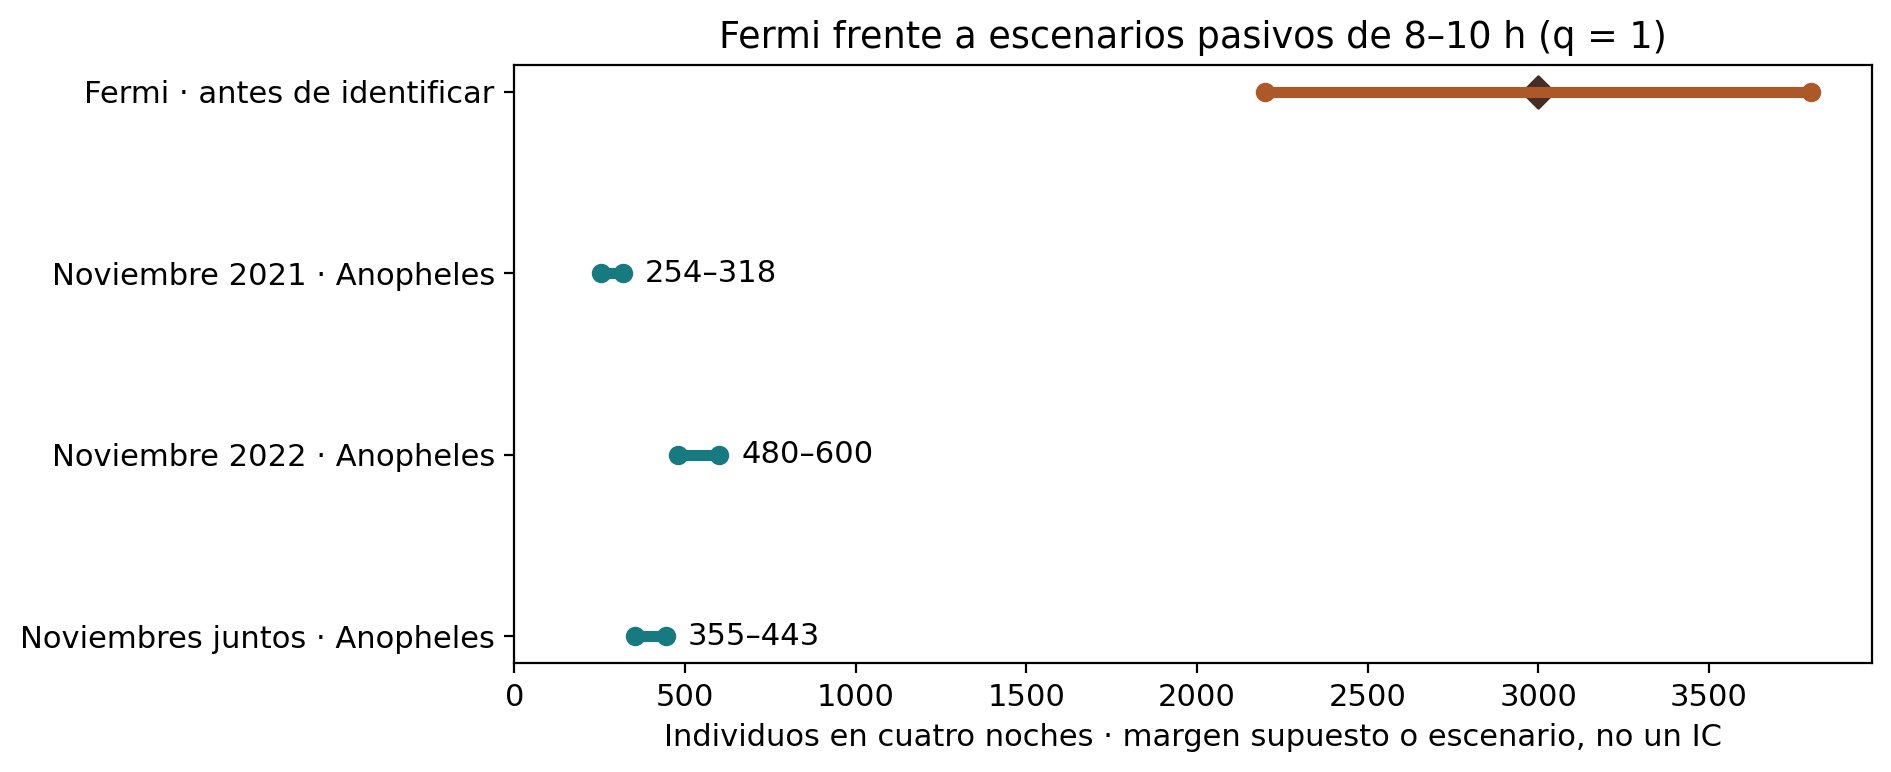

In [6]:
def tasaConjunta(tabla):
    return tabla.conteo.sum() / tabla.esfuerzo.sum()

puntosNoviembre = puntos.loc[puntos.fecha.dt.month == mesPropuesto]
visitasNoviembre = visitas.loc[visitas.fecha.dt.month == mesPropuesto]
tasaNoviembre = tasaConjunta(puntosNoviembre)
esfuerzoPropio = recipientes * nochesFermi * horasSueno
qEscenario = 1.0  # Probar 0.5 reduce el escenario pasivo a la mitad; no cambia la tasa del INS.
assert qEscenario >= 0, "El rendimiento relativo no puede ser negativo."
escenarioNoviembre = qEscenario * tasaNoviembre * esfuerzoPropio

fig, ax = plt.subplots(figsize=(9.6, 4.0))
rangoFermi = [fermiOriginal - margenOriginal, fermiOriginal + margenOriginal]
ax.plot(rangoFermi, [0, 0], "o-", lw=4, color="#ad5828")
ax.scatter(fermiOriginal, 0, marker="D", s=65, color="#462d25")
etiquetas = ["Fermi · antes de identificar"]
escenarios = [(f"Noviembre {v.fecha.year}", v.tasa) for v in visitasNoviembre.itertuples()]
for i, (nombre, tasa) in enumerate(escenarios + [("Noviembres juntos", tasaNoviembre)], 1):
    bajo, alto = qEscenario * tasa * esfuerzoPropio
    ax.plot([bajo, alto], [i, i], "o-", color="#167a80", lw=4)
    ax.annotate(f"{bajo:.0f}–{alto:.0f}", (alto, i), xytext=(8, 0), textcoords="offset points", va="center")
    etiquetas.append(nombre + " · Anopheles")
ax.set_yticks(range(len(etiquetas)), etiquetas)
ax.invert_yaxis()
ax.set(xlim=(0, None), xlabel="Individuos en cuatro noches · margen supuesto o escenario, no un IC",
       title=f"Fermi frente a escenarios pasivos de 8–10 h (q = {qEscenario:g})")
fig.tight_layout()
plt.show()

## 3. ¿Importa dónde se observa? Primero, los dos puntos de Cheté

La estrella roja de [la imagen de la hoja](Datos/cete.png) marca Chete1; la amarilla, Chete2. El sector morado es la zona que el equipo identifica como más cercana a minería. **Los códigos del ZIP no son las etiquetas «mina/población» ni «interior/exterior».** Comparamos tasas en la misma visita. Nuestra secuencia de dos noches en cada sector cambia a la vez el lugar y la fecha: permite describir, no aislar el efecto del sector.

<img src="Datos/cete.png" width="355" alt="Imagen anotada por el equipo: Chete1 en rojo, Chete2 en amarillo y sector señalado en morado.">

In [7]:
with (datos / "cauces_pacifico.geojson").open(encoding="utf-8") as fuente:
    cauces = json.load(fuente)["features"]

def dibujarCauces(eje):
    for tramo in cauces:
        lon, lat = np.asarray(tramo["geometry"]["coordinates"]).T
        eje.plot(lon, lat, color="#9fbfce", lw=1.25, zorder=1)

# Cada diferencia se calcula DENTRO de la misma visita para no mezclar temporadas.
parejas = puntos.pivot(index="visita", columns="parentEventID", values="cuatroNoches")
assert parejas.notna().all().all()
diferencias = (parejas.Chete1 - parejas.Chete2).to_numpy(dtype=float)

def indicesBloques(cantidad, largo, repeticiones=5000):
    '''Un bloque conserva visitas consecutivas; nunca se sortean mosquitos individuales.'''
    azar = np.random.default_rng(semilla)
    inicios = azar.integers(0, cantidad - largo + 1, size=(repeticiones, math.ceil(cantidad / largo)))
    bloques = inicios[:, :, None] + np.arange(largo)
    return bloques.reshape(repeticiones, -1)[:, :cantidad]

def intervaloDiferencia(valores, largo):
    muestras = valores[indicesBloques(len(valores), largo)].mean(axis=1)
    return np.quantile(muestras, [.025, .975])

icBajo, icAlto = intervaloDiferencia(diferencias, 2)
visitas12 = puntos.loc[puntos.horas == 12, "visita"].unique()
sinBase = diferencias[parejas.index.isin(visitas12)]
sinUna = [(diferencias.sum() - valor) / (len(diferencias) - 1) for valor in diferencias]
print(f"Al omitir una visita: {min(sinUna):.0f}–{max(sinUna):.0f} de diferencia media (no es un IC).")
for largo in (2, 3):
    print(f"Solo jornadas de 12 h, IC por bloques de {largo}:", intervaloDiferencia(sinBase, largo).round())

Al omitir una visita: 227–268 de diferencia media (no es un IC).
Solo jornadas de 12 h, IC por bloques de 2: [207. 371.]
Solo jornadas de 12 h, IC por bloques de 3: [205. 365.]


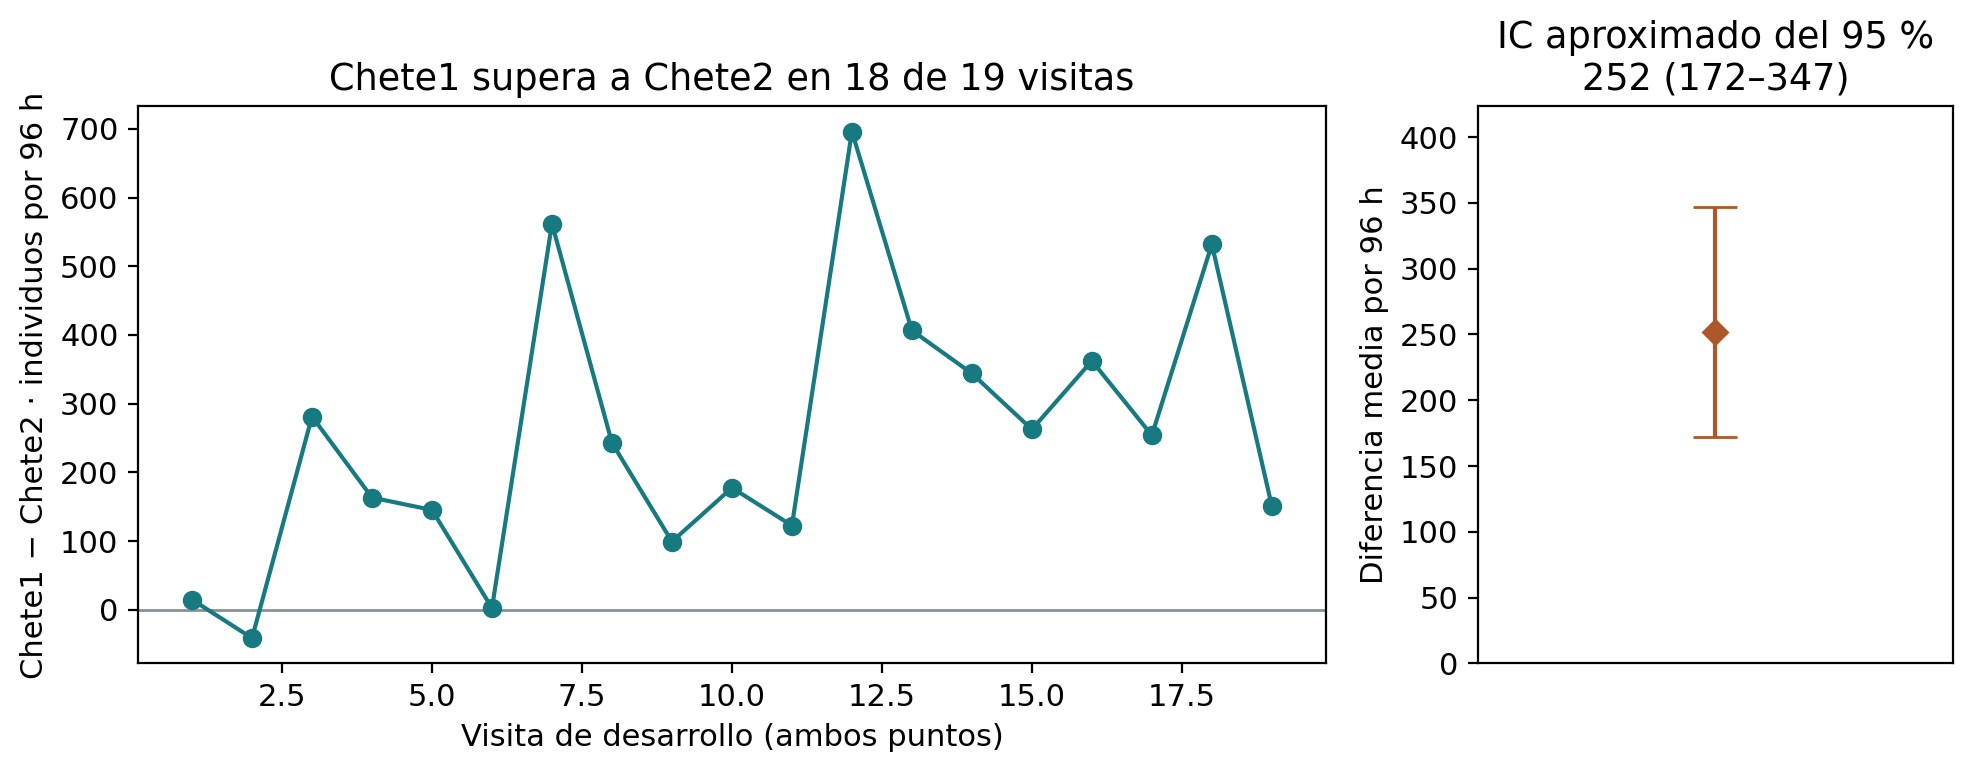

In [8]:
fig, (ax, resumen) = plt.subplots(1, 2, figsize=(10, 4.0), gridspec_kw={"width_ratios": [2.5, 1]})
ax.axhline(0, color="#85939a", lw=1)
ax.plot(parejas.index, diferencias, "o-", color="#167a80")
ax.set(xlabel="Visita de desarrollo (ambos puntos)", ylabel="Chete1 − Chete2 · individuos por 96 h",
       title=f"Chete1 supera a Chete2 en {(diferencias > 0).sum()} de {len(diferencias)} visitas")
mediaDif = diferencias.mean()
resumen.errorbar([0], [mediaDif], yerr=[[mediaDif - icBajo], [icAlto - mediaDif]],
                 fmt="D", capsize=8, color="#ad5828")
resumen.axhline(0, color="#85939a", lw=1)
resumen.set(xticks=[], ylim=(0, icAlto * 1.22), ylabel="Diferencia media por 96 h",
            title=f"IC aproximado del 95 %\n{mediaDif:.0f} ({icBajo:.0f}–{icAlto:.0f})")
fig.tight_layout()
plt.show()

## 4. ¿Noviembre y diciembre? ¿Y qué especies?

La [Fermi](../EstimacionFermi_00/estimacion_inicial.md) proponía ambos meses y, particularmente, la noche. Es razonable por la [biología descrita por los CDC](https://www.cdc.gov/mosquitoes/about/life-cycle-of-anopheles-mosquitoes.html) y por el protocolo del INS. Pero sin un grupo diurno comparable ni conteos por hora, este ZIP no demuestra una ventaja nocturna. Comparamos los meses a igual esfuerzo y marcamos los que sí se observaron: **sin visita** no significa **cero mosquitos**.

Nuestra [fuente inicial de distribución, Wikipedia](https://es.wikipedia.org/wiki/Anopheles), no es un inventario de Cheté. De *An. darlingi* y *An. albimanus* anticipadas, solo *albimanus* aparece en la tabla; las otras dos registradas son *neivai* y *apicimacula*. *An. nuneztovari* C se menciona en el contexto colombiano, no como captura del ZIP. Son hembras adultas; los palpos largos son un rasgo de referencia [bibliográfica](https://www.cdc.gov/dpdx/malaria/index.html), no una medición del archivo. Sin registros de *Aedes* ni *Culex* en un recurso dedicado a *Anopheles* no se puede inferir su ausencia en la región.

### ¿Qué cambia en noviembre y diciembre?

En Cheté comparamos cada mes del bimestre, ambos juntos y el resto de los
meses observados. Sumamos individuos y horas antes de dividir: así cada
evento pesa según su esfuerzo. Dos años de capturas, sin separar por hora
del día, no bastan para demostrar un pico estacional ni nocturno.

In [9]:
aniosContraste = [2021, 2022]
mesesBimestre = [11, 12]
sitioChete = ("Timbiquí", "Cheté")
fechasContraste = eventosDesarrollo.fecha.dropna()
if not (fechasContraste.dt.year.lt(2023) & fechasContraste.dt.day.eq(1)).all():
    raise ValueError("Los contrastes requieren meses de desarrollo anteriores a 2023.")
# Los eventos que cruzan de mes quedan fuera: no tienen un mes asignable.
eventosContraste = eventosDesarrollo.loc[eventosDesarrollo.fecha.dt.year.isin(aniosContraste)].copy()
eventosContraste["anio"] = eventosContraste.fecha.dt.year
eventosContraste["mes"] = eventosContraste.fecha.dt.month
enChete = pd.MultiIndex.from_frame(eventosContraste[camposSitio]).isin([sitioChete])
cheteCalendario = eventosContraste.loc[enChete]
mesChete = cheteCalendario.mes
gruposCalendario = {
    "Noviembre": mesChete.eq(11), "Diciembre": mesChete.eq(12),
    "Resto": ~mesChete.isin(mesesBimestre), "Bimestre": mesChete.isin(mesesBimestre),
}
tasasCalendario = pd.DataFrame(index=aniosContraste)
for nombre, filtro in gruposCalendario.items():
    totales = cheteCalendario.loc[filtro].groupby("anio")[["conteo", "esfuerzo"]].sum()
    tasasCalendario[nombre] = esfuerzoObjetivo * totales.conteo / totales.esfuerzo
assert tasasCalendario.notna().all().all()
resumenContrastes = {"bimestre": tasasCalendario.to_dict(orient="index")}

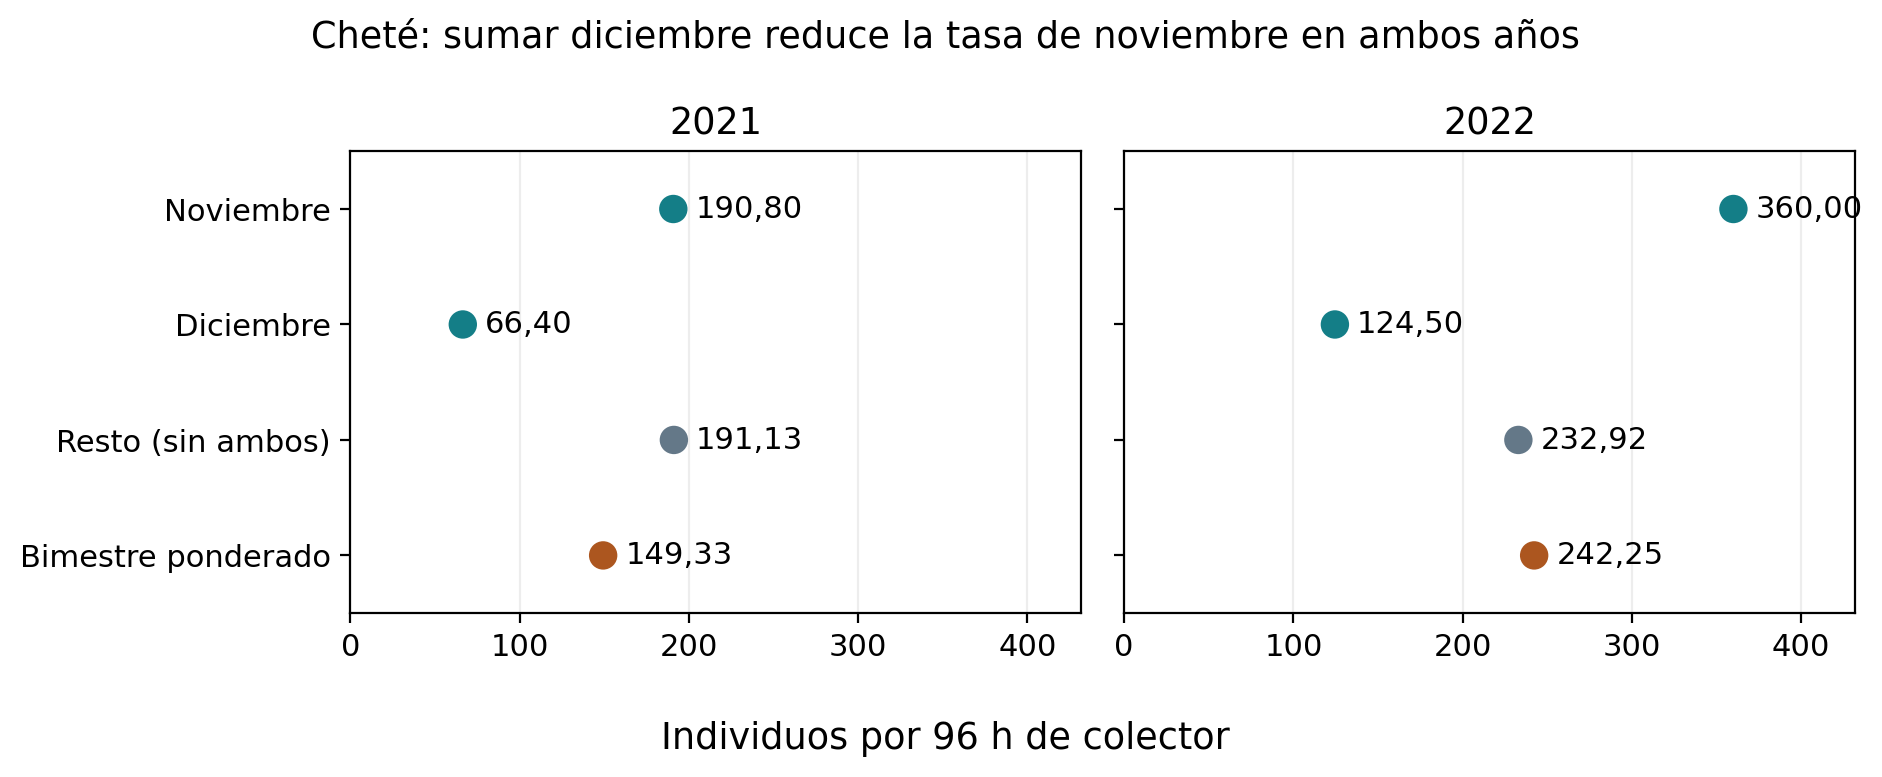

In [10]:
figBimestre, ejes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(9.6, 3.8))
categorias = ["Noviembre", "Diciembre", "Resto (sin ambos)", "Bimestre ponderado"]
for eje, (anio, tasas) in zip(ejes, tasasCalendario.iterrows()):
    orden = range(len(categorias))
    eje.scatter(tasas, orden, s=85, zorder=3,
                color=["#147e87", "#147e87", "#647888", "#ac561f"])
    for i, tasa in enumerate(tasas):
        eje.annotate(f"{tasa:.2f}".replace(".", ","), (tasa, i), xytext=(8, 0),
                     textcoords="offset points", va="center")
    eje.set_yticks(list(orden), categorias)
    eje.set(title=str(anio), ylim=(3.5, -.5),
            xlim=(0, 1.2 * tasasCalendario.max().max()))
    eje.grid(axis="x", alpha=.22)
figBimestre.supxlabel(f"Individuos por {esfuerzoObjetivo} h de colector")
figBimestre.suptitle("Cheté: sumar diciembre reduce la tasa de noviembre en ambos años")
figBimestre.tight_layout()
plt.show()

**Lectura del calendario.** Noviembre superó a diciembre en los dos años. Al comparar el bimestre completo con los demás meses observados, queda por debajo en 2021 y apenas por encima en 2022. No hay una ventaja consistente del bimestre.

### ¿Se capturaron las mismas especies dentro y fuera de Cheté?

Incluimos solo localidades con capturas en noviembre y diciembre de ambos años.
Los porcentajes describen la captura acumulada, no una localidad típica
ni la abundancia de cada especie en el ambiente.

In [11]:
# Asignar el mes por evento conserva las filas de especie sin fecha propia.
eventosBimestre = eventosContraste.loc[eventosContraste.mes.isin(mesesBimestre)]
ocurrenciasBimestre = filasRegionalesDesarrollo.merge(
    eventosBimestre[claveEvento + ["fecha"]], on=claveEvento, validate="many_to_one"
)
cobertura = ocurrenciasBimestre.groupby(camposSitio).fecha.nunique()
panel = cobertura[cobertura.eq(len(aniosContraste) * len(mesesBimestre))].index
nExternas = len(panel.drop(sitioChete))
sitios = pd.MultiIndex.from_frame(ocurrenciasBimestre[camposSitio])
enPanel = sitios.isin(panel)
panelEspecies = ocurrenciasBimestre.loc[enPanel].copy()
panelEspecies["grupo"] = np.where(sitios[enPanel].isin([sitioChete]),
                                 "Cheté", "Externas")
panelEspecies["individuos"] = panelEspecies.individualCount.astype(int)
conteosEspecies = panelEspecies.pivot_table(
    index="grupo", columns="scientificName", values="individuos", aggfunc="sum", fill_value=0
)
totalesEspecies = conteosEspecies.sum(axis=1)
porcentajesEspecies = 100 * conteosEspecies.div(totalesEspecies, axis=0)
resumenContrastes["especies"] = {
    "localidades_externas": nExternas, "totales": totalesEspecies.to_dict(),
    "conteos": conteosEspecies.to_dict(orient="index"),
}

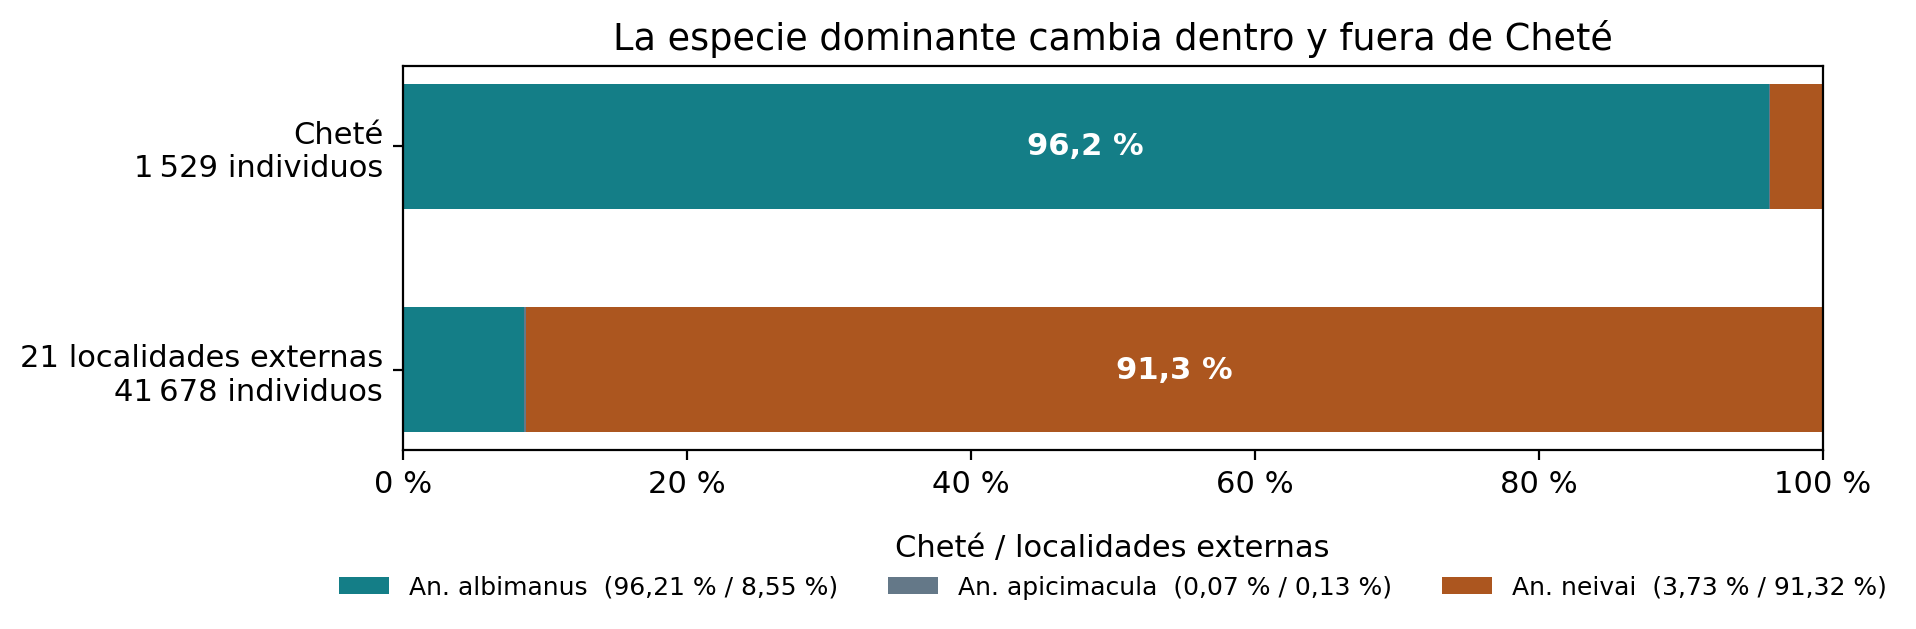

In [12]:
figEspecies, eje = plt.subplots(figsize=(9.6, 3.4))
grupos = ["Cheté", "Externas"]
nombres = ["Cheté", f"{nExternas} localidades externas"]
izquierda = np.zeros(len(grupos))
colores = ["#147e87", "#647888", "#ac561f"]
for especie, color in zip(porcentajesEspecies.columns, colores):
    anchos = porcentajesEspecies.loc[grupos, especie].to_numpy()
    porcentajes = " / ".join(f"{p:.2f} %".replace(".", ",") for p in anchos)
    nombre = especie.replace("Anopheles ", "An. ")
    eje.barh(grupos, anchos, left=izquierda, height=.56, color=color,
             label=f"{nombre}  ({porcentajes})")
    for y, ancho in enumerate(anchos):
        if ancho > 50:
            eje.text(izquierda[y] + ancho/2, y, f"{ancho:.1f} %".replace(".", ","),
                     ha="center", va="center", color="white", fontweight="bold")
    izquierda += anchos
eje.set_yticks(range(len(grupos)), [
    f"{nombre}\n{totalesEspecies[g]:,} individuos".replace(",", "\u202f")
    for nombre, g in zip(nombres, grupos)
])
eje.invert_yaxis()
eje.set(xlim=(0, 100), title="La especie dominante cambia dentro y fuera de Cheté")
eje.set_xticks(range(0, 101, 20), [f"{p} %" for p in range(0, 101, 20)])
eje.legend(title="Cheté / localidades externas", loc="upper center",
           bbox_to_anchor=(.5, -.16), ncol=3, frameon=False, fontsize=9)
figEspecies.tight_layout()
plt.show()

En los cuatro meses comparables dominó *albimanus* en Cheté (1.471 de 1.529) y *neivai* en el panel externo (38.059 de 41.678). Esa diferencia no convierte a ninguno de los grupos en un inventario de todos los mosquitos.

## 5. ¿Se repite la diferencia entre puntos fuera de Cheté?

Para cada par de puntos de una misma localidad usamos solo los meses de
calendario observados en ambos puntos y ambos años. Restamos las tasas
mensuales en el mismo orden y comparamos el signo de la mediana de cada
año. Exigimos al menos tres meses comunes; como comprobación, pedimos
cinco y una coordenada única conocida y distinta para cada punto.

Los pares pueden compartir puntos: no son observaciones independientes.
La concordancia no identifica efectos de la mina, los gases u otras causas;
los códigos de punto no representan exposiciones.

In [13]:
from itertools import combinations

externos = eventosContraste.loc[~enChete]
clavePunto = [*camposSitio, "punto"]
mensual = externos.groupby(clavePunto + ["anio", "mes"], as_index=False)[["conteo", "esfuerzo"]].sum()
mensual["tasa"] = esfuerzoObjetivo * mensual.conteo / mensual.esfuerzo
lon, lat = "decimalLongitude", "decimalLatitude"
coordenadasDesarrollo = filasRegionalesDesarrollo.loc[
    filasRegionalesDesarrollo.geodeticDatum.eq("WGS84"), [*camposSitio, "parentEventID", lon, lat]
].rename(columns={"parentEventID": "punto"})
coordenadasDesarrollo[[lon, lat]] = coordenadasDesarrollo[[lon, lat]].apply(pd.to_numeric, errors="coerce")
validas = coordenadasDesarrollo[lon].between(-180, 180) & coordenadasDesarrollo[lat].between(-90, 90)
# No elegimos entre coordenadas contradictorias de un mismo punto.
posicionesPares = (coordenadasDesarrollo.loc[validas].drop_duplicates()
                   .drop_duplicates(clavePunto, keep=False).set_index(clavePunto))
filasPares = []
for sitio, tabla in mensual.groupby(camposSitio):
    tasas = tabla.pivot(index="mes", columns=["punto", "anio"], values="tasa")
    for a, b in combinations(sorted(tabla.punto.unique()), 2):
        columnas = [(punto, anio) for punto in (a, b) for anio in aniosContraste]
        comunes = tasas.reindex(columns=columnas).dropna()
        if len(comunes) < 3:
            continue
        medianas = (comunes[a] - comunes[b]).median()
        ubicaciones = posicionesPares.reindex([(*sitio, a), (*sitio, b)]).dropna()
        estricto = len(comunes) >= 5 and len(ubicaciones.drop_duplicates()) == 2
        filasPares.append((*sitio, *medianas, len(comunes), estricto))
primero, segundo = aniosContraste
pares = pd.DataFrame(filasPares, columns=[*camposSitio, primero, segundo, "n_meses", "estricto"])
producto = pares[primero] * pares[segundo]
pares["signo"] = np.select([producto.gt(0), producto.lt(0)], ["Conserva", "Cambia"], "Mediana cero")
resumenContrastes["pares"] = {
    nombre: {"conservan": int(tabla.signo.eq("Conserva").sum()), "n_pares": len(tabla),
             "n_localidades": len(tabla[camposSitio].drop_duplicates())}
    for nombre, tabla in [("base", pares), ("cinco_meses", pares.loc[pares.n_meses >= 5]),
                          ("sensibilidad", pares.loc[pares.estricto])]
}

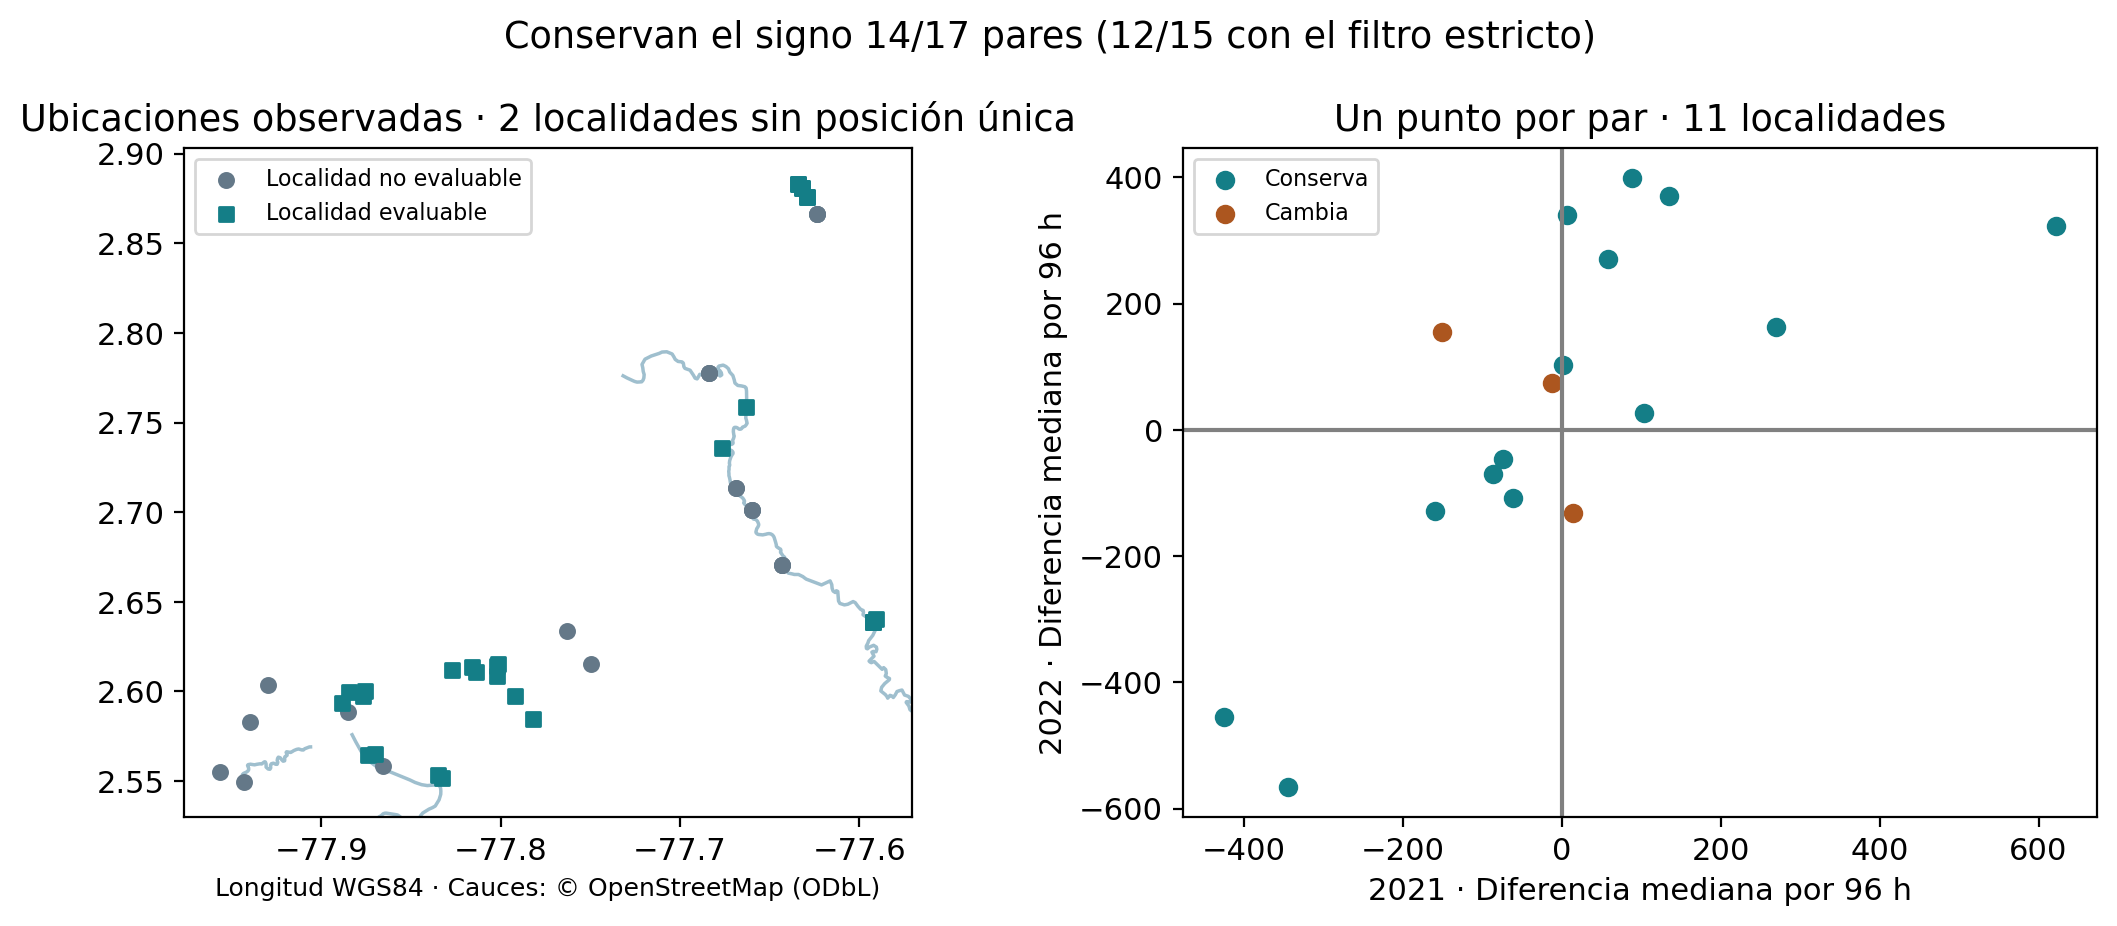

In [14]:
figPares, (mapa, nube) = plt.subplots(1, 2, figsize=(10.8, 4.7))
dibujarCauces(mapa)
localidades = pd.MultiIndex.from_frame(externos[camposSitio].drop_duplicates())
evaluables = pd.MultiIndex.from_frame(pares[camposSitio].drop_duplicates())
puntosMapa = posicionesPares.loc[posicionesPares.index.droplevel("punto").isin(localidades)].reset_index()
sitiosMapa = pd.MultiIndex.from_frame(puntosMapa[camposSitio])
hayPar = sitiosMapa.isin(evaluables)
for mascara, etiqueta, marcador, color in [
    (~hayPar, "Localidad no evaluable", "o", "#647888"),
    (hayPar, "Localidad evaluable", "s", "#147e87"),
]:
    ubicaciones = puntosMapa.loc[mascara]
    mapa.scatter(ubicaciones[lon], ubicaciones[lat], marker=marcador,
                 color=color, s=26, label=etiqueta, zorder=3)
margenMapa = .02  # Grados de margen alrededor de las posiciones observadas.
if len(puntosMapa):
    mapa.set(xlim=(puntosMapa[lon].min() - margenMapa, puntosMapa[lon].max() + margenMapa),
             ylim=(puntosMapa[lat].min() - margenMapa, puntosMapa[lat].max() + margenMapa))
sinMapa = len(localidades.difference(sitiosMapa))
mapa.set(title=f"Ubicaciones observadas · {sinMapa} localidades sin posición única", aspect="equal")
mapa.set_xlabel("Longitud WGS84 · Cauces: © OpenStreetMap (ODbL)", fontsize=9)
mapa.legend(loc="upper left", fontsize=8)
coloresSigno = {"Conserva": "#147e87", "Cambia": "#ac561f", "Mediana cero": "#647888"}
for signo, grupo in pares.groupby("signo", sort=False):
    nube.scatter(grupo[primero], grupo[segundo], color=coloresSigno[signo], label=signo)
nube.axhline(0, color=".5")
nube.axvline(0, color=".5")
basePares, filtroPares = (resumenContrastes["pares"][k] for k in ["base", "sensibilidad"])
unidad = f"Diferencia mediana por {esfuerzoObjetivo} h"
nube.set(title=f"Un punto por par · {basePares['n_localidades']} localidades",
         xlabel=f"{primero} · {unidad}", ylabel=f"{segundo} · {unidad}")
nube.legend(fontsize=8)
figPares.suptitle(f"Conservan el signo {basePares['conservan']}/{basePares['n_pares']} pares "
                 f"({filtroPares['conservan']}/{filtroPares['n_pares']} con el filtro estricto)")
figPares.tight_layout()
plt.show()

## 6. ¿Qué historia usamos para predecir una visita?

Antes de evaluar el bloque final comparamos dos formas de ganar datos: **A**, la misma localidad en distintos meses, y **B**, distintas localidades de Timbiquí en noviembre. Se elige la menor dispersión relativa promedio por año en desarrollo. No es una competencia en el bloque de prueba, y la elección A/B tampoco es independiente de las validaciones de 2022.

In [15]:
opciones = {"A": "Cheté, todos los meses", "B": "Timbiquí, noviembre"}
def dispersionPorAnio(eventos):
    x = eventos.dropna(subset=["fecha"]).assign(anio=lambda t: t.fecha.dt.year)
    timbiqui = x.loc[x.county == "Timbiquí"]
    muestras = {"A": (timbiqui.loc[timbiqui.locality == "Cheté"], "fecha"),
                "B": (timbiqui.loc[timbiqui.fecha.dt.month == mesPropuesto], "locality")}
    filas = []
    for opcion, (muestra, unidad) in muestras.items():
        grupos = muestra.groupby(["anio", unidad])[["conteo", "esfuerzo"]].sum()
        tasas = grupos.conteo / grupos.esfuerzo
        for anio, serie in tasas.groupby(level="anio"):
            cv = serie.std() / serie.mean()
            robusta = (serie.quantile(.75) - serie.quantile(.25)) / serie.median()
            filas.append((opcion, anio, cv, robusta))
    return pd.DataFrame(filas, columns=["opcion", "anio", "CV", "RIC/mediana"])

dispersion = dispersionPorAnio(eventosDesarrollo)
promedio = dispersion.groupby("opcion").CV.mean()
opcionElegida = promedio.idxmin()
print(f"A: {promedio['A']:.1%} · B: {promedio['B']:.1%}. Menor promedio: {opciones[opcionElegida]}.")
# Cambiar la duración o usar otra medida comprueba si el alcance era frágil.
jornadas12 = dispersionPorAnio(eventosDesarrollo.loc[eventosDesarrollo.horas == 12])
print("Menor CV con jornadas de 12 h:", jornadas12.groupby("opcion").CV.mean().idxmin(),
      "· con RIC/mediana:", dispersion.groupby("opcion")["RIC/mediana"].mean().idxmin())

A: 47.8% · B: 63.5%. Menor promedio: Cheté, todos los meses.
Menor CV con jornadas de 12 h: A · con RIC/mediana: A


**Incertidumbre del promedio.** Dentro de Cheté, A no gana en cada año, pero sí en promedio. Para la tasa histórica del desarrollo, el IC se obtiene remuestreando visitas completas en bloques de dos o tres, con los puntos juntos. No es el intervalo de una nueva visita ni una banda para los frascos.

In [16]:
conteos = visitas.conteo.to_numpy(dtype=float)
horas = visitas.esfuerzo.to_numpy(dtype=float)
for largo in (2, 3):
    indices = indicesBloques(len(visitas), largo)
    promedio96 = esfuerzoObjetivo * conteos[indices].sum(axis=1) / horas[indices].sum(axis=1)
    bajo, alto = np.quantile(promedio96, [.025, .975])
    print(f"Bloques de {largo}: promedio {esfuerzoObjetivo*tasaConjunta(visitas):.0f}, "
          f"IC 95 % ≈ {bajo:.0f}–{alto:.0f} por 96 h.")

Bloques de 2: promedio 210, IC 95 % ≈ 177–247 por 96 h.
Bloques de 3: promedio 210, IC 95 % ≈ 173–246 por 96 h.


### El cierre anterior a enero de 2023

Reproducimos el cierre histórico de Poisson antes de mirar los conteos reservados. Las primeras dos ventanas eligieron regularización; las dos siguientes calibraron el margen con seis visitas. La firma documenta el ajuste con las versiones indicadas, no la fecha de publicación. Los bosques que siguen son una ampliación retrospectiva.

In [17]:
def variables(fecha):
    # Dos componentes del mes evitan un salto artificial entre diciembre y enero.
    fecha = pd.DatetimeIndex(fecha)
    meses = (fecha.year - 2021) * 12 + fecha.month - 1
    angulo = 2 * np.pi * (fecha.month - 1) / 12
    return np.column_stack([meses / 12, np.sin(angulo), np.cos(angulo)])

def ajustar(entrenamiento, alpha):
    escala = StandardScaler()
    x = escala.fit_transform(variables(entrenamiento.fecha))
    modelo = PoissonRegressor(alpha=alpha, max_iter=2000, tol=1e-8)
    modelo.fit(x, entrenamiento.tasa.to_numpy(dtype=float),
               sample_weight=entrenamiento.esfuerzo.to_numpy(dtype=float))
    return escala, modelo

def predecir(ajuste, fechas):
    escala, modelo = ajuste
    return esfuerzoObjetivo * modelo.predict(escala.transform(variables(fechas)))

def referencias(entrenamiento, cantidad):
    return {
        "Última visita": np.repeat(entrenamiento.cuatroNoches.iloc[-1], cantidad),
        "Fermi revisada": np.repeat(esfuerzoObjetivo * tasaConjunta(entrenamiento), cantidad)
    }

In [18]:
bloques = [(7, 10), (10, 13), (13, 16), (16, 19)]
for inicio, fin in bloques:
    assert visitas.iloc[:inicio].fin.max() < visitas.iloc[inicio:fin].inicio.min()

def erroresPoisson(alpha, ventanas):
    errores = []
    for inicio, fin in ventanas:
        antes, despues = visitas.iloc[:inicio], visitas.iloc[inicio:fin]
        pred = predecir(ajustar(antes, alpha), despues.fecha)
        errores.extend(abs(despues.cuatroNoches.to_numpy(dtype=float) - pred))
    return np.asarray(errores)

candidatos = (0.01, 0.1, 1.0, 10.0)
alphaElegido = min(candidatos, key=lambda a: erroresPoisson(a, bloques[:2]).mean())
erroresCal = {"Poisson": erroresPoisson(alphaElegido, bloques[2:]), "Última visita": [], "Fermi revisada": []}
for inicio, fin in bloques[2:]:
    antes, despues = visitas.iloc[:inicio], visitas.iloc[inicio:fin]
    for nombre, pred in referencias(antes, len(despues)).items():
        erroresCal[nombre].extend(abs(despues.cuatroNoches.to_numpy(dtype=float) - pred))

def margenEmpirico(errores, nivel=.80):
    # El rango superior, no el percentil interpolado: con seis visitas corresponde al mayor error.
    rango = math.ceil((len(errores) + 1) * nivel)
    if rango > len(errores):
        raise ValueError("La muestra no alcanza para ese nivel.")
    return float(np.sort(errores)[rango - 1])

margenes = {nombre: margenEmpirico(errores) for nombre, errores in erroresCal.items()}

In [19]:
ajusteCerrado = ajustar(visitas, alphaElegido)
configuracionCerrada = {
    "archivo": huella, "alpha": alphaElegido, "esfuerzo": esfuerzoObjetivo,
    "variables": ["tiempo", "seno del mes", "coseno del mes"],
    "reserva": sorted(eventosReserva), "margenes": margenes,
    "coeficientes": ajusteCerrado[1].coef_.tolist(),
    "intercepto": float(ajusteCerrado[1].intercept_),
    "mediaEscala": ajusteCerrado[0].mean_.tolist(),
    "escala": ajusteCerrado[0].scale_.tolist()
}
firmaModelo = sha256(json.dumps(configuracionCerrada, sort_keys=True).encode()).hexdigest()
print("Configuración cerrada:", firmaModelo)
fechasReserva = pd.date_range("2023-01-01", periods=3, freq="MS")
pronosticoCerrado = predecir(ajusteCerrado, fechasReserva)
print("Pronósticos cerrados de enero a marzo:", np.round(pronosticoCerrado, 2))

Configuración cerrada: ab3f65bc26c4696fc255c62a8aa83c18a1797b9839da3ffd229437be5b02de3c
Pronósticos cerrados de enero a marzo: [213.34 214.1  215.81]


## 7. ¿Cuánto podemos anticipar en Cheté?

Ajustamos dos bosques con la misma receta: 200 árboles, profundidad máxima 3,
mínimo de 3 visitas por hoja y semilla 829. El regional usa todas las visitas
localidad–mes fechables de desarrollo; el focal usa el alcance elegido allí por
menor dispersión media: **A, todos los meses de Cheté**, frente a **B, localidades de
Timbiquí en noviembre**. Elegir A no cambia la hipótesis original sobre noviembre
y diciembre.

Cada bosque estima una tasa y la multiplica por 96 horas de colector. Las entradas
son la etiqueta municipio–localidad, el tiempo transcurrido y el ciclo anual
(seno y coseno del mes), y la última tasa disponible en el alcance de ese bosque.
El esfuerzo pondera el ajuste; no es un predictor. Las referencias usan solo
Cheté: su tasa histórica (total de individuos / total de horas) y su última visita.

In [20]:
def formarCampanas(eventos):
    fechados = eventos.loc[eventos.fecha.notna()]
    campanas = fechados.groupby(camposSitio + ["fecha"], as_index=False).agg(
        conteo=("conteo", "sum"), esfuerzo=("esfuerzo", "sum"),
        fin=("fin", "max"), eventos=("eventID", "size"),
    )
    campanas["tasa"] = campanas.conteo / campanas.esfuerzo
    campanas["sitio"] = campanas.county.str.cat(campanas.locality, sep=" · ")
    assert campanas.fin.lt(campanas.fecha + pd.offsets.MonthBegin()).all()
    return campanas.sort_values(["fecha", "sitio"]).reset_index(drop=True)


campanasDesarrollo = formarCampanas(eventosDesarrollo)
cheteDesarrollo = campanasDesarrollo.loc[campanasDesarrollo.sitio.eq(localidadObjetivo)]
assert len(cheteDesarrollo) == len(visitas) and cheteDesarrollo.eventos.eq(2).all()
assert np.allclose(cheteDesarrollo.tasa, visitas.tasa)

bosqueRegional, bosqueFocal = "Bosque regional", f"Bosque focal ({opcionElegida})"
nombreHistorica, nombreUltima = "Tasa histórica", "Última visita"
nombresBosques = [bosqueRegional, bosqueFocal]
metodos = nombresBosques + [nombreHistorica, nombreUltima]
calendarioBosque = ["tiempo", "senoMes", "cosenoMes"]
parametrosBosque = dict(n_estimators=200, max_depth=3, min_samples_leaf=3,
                       random_state=semilla, n_jobs=1)


def entradasBosque(visitasMes, tasaAnterior):
    mes = visitasMes.fecha.dt.month.to_numpy()
    angulo = 2 * np.pi * (mes - 1) / 12
    return pd.DataFrame({
        "sitio": visitasMes.sitio.to_numpy(),
        "tiempo": 12 * (visitasMes.fecha.dt.year.to_numpy() - 2021) + mes - 1,
        "senoMes": np.sin(angulo), "cosenoMes": np.cos(angulo),
        "tasaAnterior": tasaAnterior.to_numpy(dtype=float),
    })

In [21]:
def ajustarBosques(pasado, corte):
    assert pasado.fin.lt(corte).all()
    if opcionElegida == "A":
        focal = pasado.loc[pasado.sitio.eq(localidadObjetivo)]
    else:
        focal = pasado.loc[pasado.county.eq("Timbiquí") & pasado.fecha.dt.month.eq(mesPropuesto)]

    ajustes = {}
    for nombre, muestra in [(bosqueRegional, pasado), (bosqueFocal, focal)]:
        # formarCampanas ya ordenó por fecha; shift usa SOLO la visita anterior de ese sitio.
        tasas = muestra.groupby("sitio").tasa
        # -1 identifica una tasa no disponible; cero sería una captura real.
        anterior = tasas.shift().fillna(-1)
        codificar = ColumnTransformer([
            ("numeros", "passthrough", calendarioBosque + ["tasaAnterior"]),
            ("lugar", OneHotEncoder(handle_unknown="ignore"), ["sitio"]),
        ])
        bosque = make_pipeline(codificar, RandomForestRegressor(**parametrosBosque))
        bosque.fit(entradasBosque(muestra, anterior), muestra.tasa,
                   randomforestregressor__sample_weight=muestra.esfuerzo)
        ajustes[nombre] = (bosque, tasas.last())
    return ajustes, len(focal)


def pronosticar(ajustes, pasado, objetivos):
    entradas, pred = {}, {}
    for nombre, (bosque, ultimaPorSitio) in ajustes.items():
        anterior = objetivos.sitio.map(ultimaPorSitio).fillna(-1)
        entradas[nombre] = entradasBosque(objetivos, anterior)
        pred[nombre] = esfuerzoObjetivo * bosque.predict(entradas[nombre])
    chete = pasado.loc[pasado.sitio.eq(localidadObjetivo)]
    pred[nombreHistorica] = esfuerzoObjetivo * tasaConjunta(chete)
    pred[nombreUltima] = esfuerzoObjetivo * chete.tasa.iloc[-1]
    return pd.DataFrame(pred, index=objetivos.index), entradas

En 2022 simulamos pronósticos con cortes sucesivos. En cada simulación una visita
entra al entrenamiento solo si **terminó antes del corte**; la última tasa queda
fija al pronosticar. Medimos el error absoluto medio (MAE) a un mes en las diez visitas
de Cheté. También recalculamos los errores a dos y tres meses, conservando al menos
la historia usada en el primer ejercicio a un mes. Estos ejercicios no son una prueba
independiente de A/B, cuya elección vio todo el desarrollo.

Para cada método y adelanto, ordenamos los errores absolutos y tomamos el de posición
$\lceil 0{,}80\,(n+1)\rceil$. Ese margen al 80 % es **orientativo**: hay pocos cortes y no
podemos garantizar cobertura futura. Fijamos los pronósticos y márgenes del bloque
enero–marzo de 2023 desde un único corte, sin actualizar con capturas del bloque.

In [22]:
fechasValidacion = cheteDesarrollo.loc[cheteDesarrollo.fecha.dt.year.eq(2022), "fecha"]
minimoHistoria = cheteDesarrollo.fin.lt(fechasValidacion.min()).sum()
erroresPorHorizonte, margenesHorizonte, ajustesPorCorte = {}, {}, {}
casosRegion = []
casosChete = {nombre: [] for nombre in nombresBosques}

for horizonte in (1, 2, 3):
    errores = []
    for fecha in fechasValidacion:
        corte = fecha - pd.DateOffset(months=horizonte - 1)
        if cheteDesarrollo.fin.lt(corte).sum() < minimoHistoria:
            continue
        if corte not in ajustesPorCorte:
            pasado = campanasDesarrollo.loc[campanasDesarrollo.fin.lt(corte)]
            ajustes, _ = ajustarBosques(pasado, corte)
            ajustesPorCorte[corte] = (pasado, ajustes)
        pasado, ajustes = ajustesPorCorte[corte]
        objetivos = campanasDesarrollo.loc[campanasDesarrollo.fecha.eq(fecha)]
        # Conservamos los otros sitios solo a un mes, para la importancia regional.
        if horizonte > 1:
            objetivos = objetivos.loc[objetivos.sitio.eq(localidadObjetivo)]
        esChete = objetivos.sitio.eq(localidadObjetivo).to_numpy()
        assert esChete.sum() == 1 and pasado.fin.max() < corte <= fecha
        pred, entradas = pronosticar(ajustes, pasado, objetivos)
        observado = esfuerzoObjetivo * objetivos.tasa.to_numpy(dtype=float)
        errores.append((pred.loc[esChete].iloc[0] - observado[esChete][0]).abs())
        if horizonte == 1:
            casosRegion.append((ajustes[bosqueRegional][0], entradas[bosqueRegional], observado))
            for nombre in nombresBosques:
                casosChete[nombre].append(
                    (ajustes[nombre][0], entradas[nombre].loc[esChete], observado[esChete])
                )

    errores = pd.DataFrame(errores)
    posicion = math.ceil(.80 * (len(errores) + 1))
    assert posicion <= len(errores), "No hay suficientes ejercicios para calibrar este adelanto."
    margen = errores.apply(lambda columna: np.sort(columna)[posicion - 1])
    erroresPorHorizonte[horizonte] = errores
    margenesHorizonte[horizonte] = margen
    print(f"Adelanto {horizonte} · {len(errores)} ejercicios · "
          f"margen de la tasa histórica: ±{margen[nombreHistorica]:.0f} por 96 h.")

Adelanto 1 · 10 ejercicios · margen de la tasa histórica: ±155 por 96 h.


Adelanto 2 · 9 ejercicios · margen de la tasa histórica: ±155 por 96 h.


Adelanto 3 · 8 ejercicios · margen de la tasa histórica: ±268 por 96 h.


In [23]:
mae2022 = erroresPorHorizonte[1].mean()
ajustesFinales, nFocal = ajustarBosques(campanasDesarrollo, corteFinal)
fechasBloque = pd.date_range(corteFinal, periods=3, freq="MS")
assert fechasBloque.tolist() == pd.to_datetime(sorted(reserva.periodo.unique())).tolist()
objetivoBloque = pd.DataFrame({"sitio": localidadObjetivo, "fecha": fechasBloque})
predBloque, _ = pronosticar(ajustesFinales, campanasDesarrollo, objetivoBloque)
margenBloque = pd.DataFrame([margenesHorizonte[h] for h in (1, 2, 3)])
inferiores = (predBloque - margenBloque).clip(lower=0)
superiores = predBloque + margenBloque
print(f"Corte {corteFinal.date()} · {len(campanasDesarrollo)} visitas regionales "
      f"({campanasDesarrollo.sitio.nunique()} etiquetas) y {nFocal} focales · "
      f"alcance {opcionElegida}: {opciones[opcionElegida]}.")

Corte 2023-01-01 · 483 visitas regionales (27 etiquetas) y 19 focales · alcance A: Cheté, todos los meses.


### Evaluación retrospectiva: enero–marzo de 2023

Ahora abrimos las visitas 20–22. Este bloque fue reservado originalmente para el
modelo de Poisson: respetamos la frontera temporal en el ajuste de los bosques, pero
sus resultados ya eran conocidos al plantear esta comparación. **No es un nuevo
conjunto de prueba independiente.**

Menor MAE en 2022: Tasa histórica. En el bloque de 2023: Última visita.
La banda orientativa de la tasa histórica contiene 3 de 3 observaciones; no es una validación de cobertura.
Referencia recomendada: Tasa histórica.


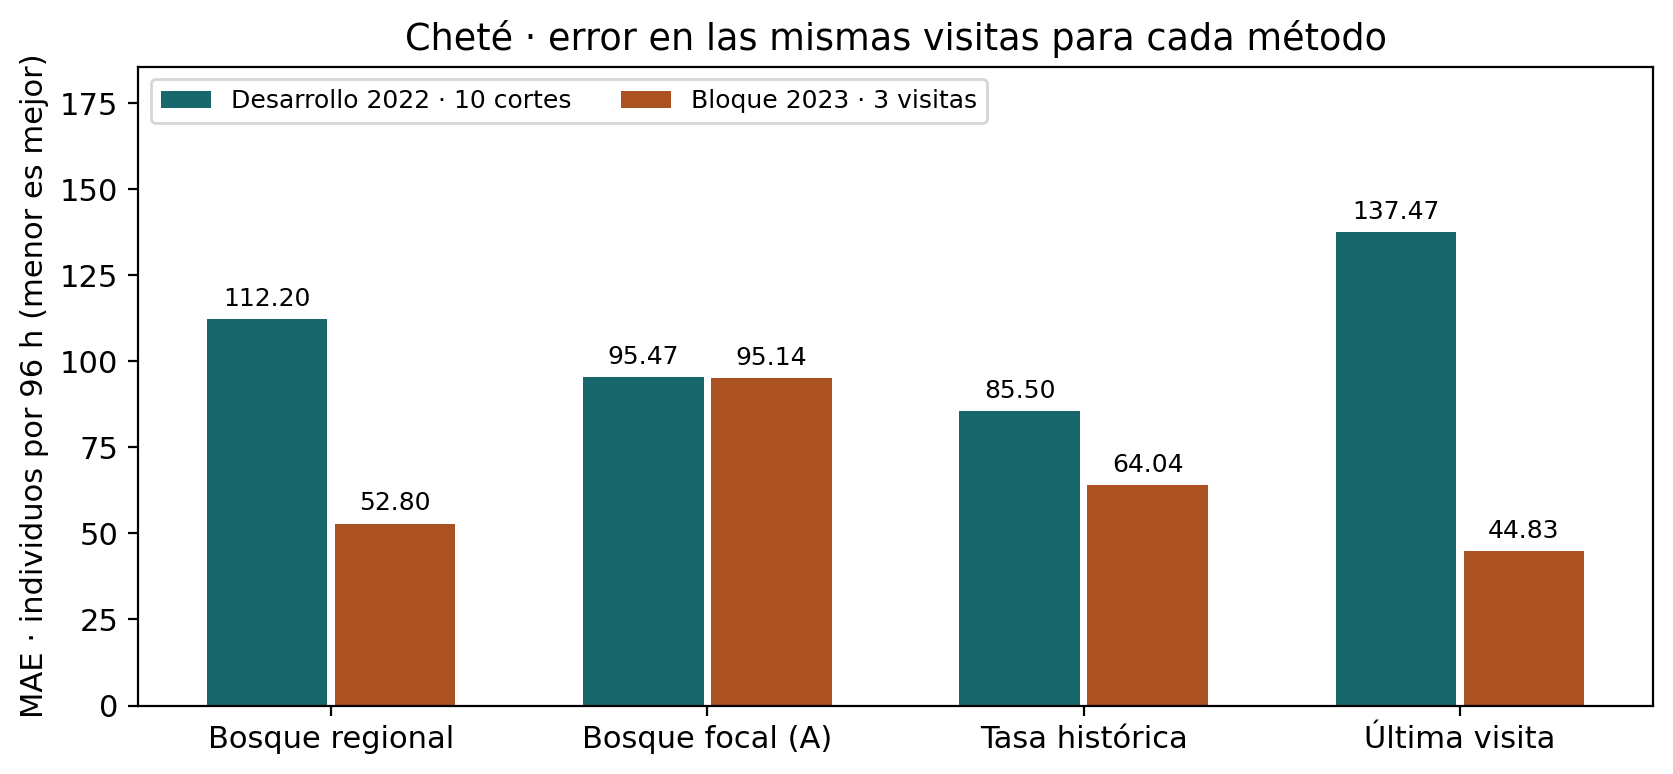

In [24]:
pruebaOriginal = leerFilas(filasReserva)
assert set(pruebaOriginal.eventID) == set(reserva.eventID)
pruebaPreparada = preparar(pruebaOriginal)
_, prueba = agruparVisitas(pruebaPreparada)
assert prueba.visita.tolist() == [20, 21, 22]
assert prueba.fecha.tolist() == fechasBloque.tolist()
assert prueba.inicio.ge(corteFinal).all()

observadoBloque = prueba.cuatroNoches.to_numpy(dtype=float)
mae2023 = predBloque.sub(observadoBloque, axis=0).abs().mean()
cubre = inferiores.le(observadoBloque, axis=0) & superiores.ge(observadoBloque, axis=0)
print(f"Menor MAE en 2022: {mae2022.idxmin()}. En el bloque de 2023: {mae2023.idxmin()}.")
print(f"La banda orientativa de la tasa histórica contiene "
      f"{cubre[nombreHistorica].sum()} de 3 observaciones; no es una validación de cobertura.")

# Solo sustituimos la tasa histórica si un bosque gana a las dos referencias en ambos ejercicios.
referenciasBosques = [nombreHistorica, nombreUltima]
consistentes = [
    n for n in nombresBosques
    if mae2022[n] < mae2022[referenciasBosques].min() and mae2023[n] < mae2023[referenciasBosques].min()
]
recomendado = min(consistentes, key=mae2022.get) if consistentes else nombreHistorica
print(f"Referencia recomendada: {recomendado}.")

figValidacion, ax = plt.subplots(figsize=(8.5, 4))
posiciones = np.arange(len(metodos))
for errores, desplazamiento, color, etiqueta in [
    (mae2022, -.17, "#17676d", "Desarrollo 2022 · 10 cortes"),
    (mae2023, .17, "#ac5222", "Bloque 2023 · 3 visitas"),
]:
    barras = ax.bar(posiciones + desplazamiento, errores[metodos], .32,
                    color=color, label=etiqueta)
    ax.bar_label(barras, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(posiciones, metodos)
ax.set(ylabel="MAE · individuos por 96 h (menor es mejor)",
       title="Cheté · error en las mismas visitas para cada método")
ax.set_ylim(0, 1.35 * max(mae2022.max(), mae2023.max()))
ax.legend(loc="upper left", fontsize=9, ncol=2)
figValidacion.tight_layout()
plt.show()

En desarrollo ganó la **tasa histórica**; en las tres visitas de 2023, la **última
visita**. Ningún bosque mejoró ambas referencias en los dos ejercicios. Por eso
conservamos la tasa histórica como referencia de planificación, no porque haya
ganado el bloque final.

<a id="importancia-random-forest"></a>

### 7.1. ¿Qué predictores ayudaron al bosque?

Medimos cuánto cambia el MAE en las visitas de validación de 2022 al mezclar cada
grupo. Mezclamos la última tasa y el calendario **entre meses de un mismo sitio**,
y la etiqueta de localidad **entre sitios del mismo mes**. En Cheté la etiqueta no
cambia, así que no se puede evaluar allí. El punto indica el cambio medio; el
segmento, los percentiles 10 y 90 de 60 mezclas, no un intervalo de confianza.

In [25]:
def importanciaBloques(casos, grupos, porMes=False, repeticiones=60):
    entradas = pd.concat([x for _, x, _ in casos], ignore_index=True)
    observado = np.concatenate([y for _, _, y in casos])
    # Un tramo por corte: cada predicción vuelve al modelo entrenado para ese corte.
    tramos = np.split(np.arange(len(entradas)), np.cumsum([len(x) for _, x, _ in casos])[:-1])
    bloques = tramos if porMes else entradas.groupby("sitio", sort=False).indices.values()
    original = np.concatenate([esfuerzoObjetivo * bosque.predict(x) for bosque, x, _ in casos])
    maeOriginal = np.abs(original - observado).mean()

    azar = np.random.default_rng(semilla)
    ordenes = np.tile(np.arange(len(entradas)), (repeticiones, 1))
    for orden in ordenes:
        for bloque in bloques:
            orden[bloque] = azar.permutation(bloque)

    resultados = []
    for variable, columnas in grupos.items():
        sumaErrores = np.zeros(repeticiones)
        # Cada visita conserva el bosque de su corte; agrupamos las 60 mezclas al predecir.
        for (bosque, x, y), tramo in zip(casos, tramos):
            lote = pd.concat([x] * repeticiones, ignore_index=True)
            lote[columnas] = entradas.iloc[ordenes[:, tramo].ravel()][columnas].to_numpy()
            simuladas = esfuerzoObjetivo * bosque.predict(lote).reshape(repeticiones, len(x))
            sumaErrores += np.abs(simuladas - y).sum(axis=1)
        cambio = sumaErrores / len(observado) - maeOriginal
        resultados.append([variable, cambio.mean(), *np.quantile(cambio, [.10, .90])])
    return pd.DataFrame(resultados, columns=["Variable", "Cambio", "P10", "P90"])


gruposTemporales = {"Última tasa": ["tasaAnterior"], "Calendario": calendarioBosque}
impRegional = pd.concat([
    importanciaBloques(casosRegion, gruposTemporales),
    importanciaBloques(casosRegion, {"Localidad": ["sitio"]}, porMes=True),
]).sort_values("Cambio", ascending=False)
impChete = {n: importanciaBloques(casosChete[n], gruposTemporales) for n in nombresBosques}

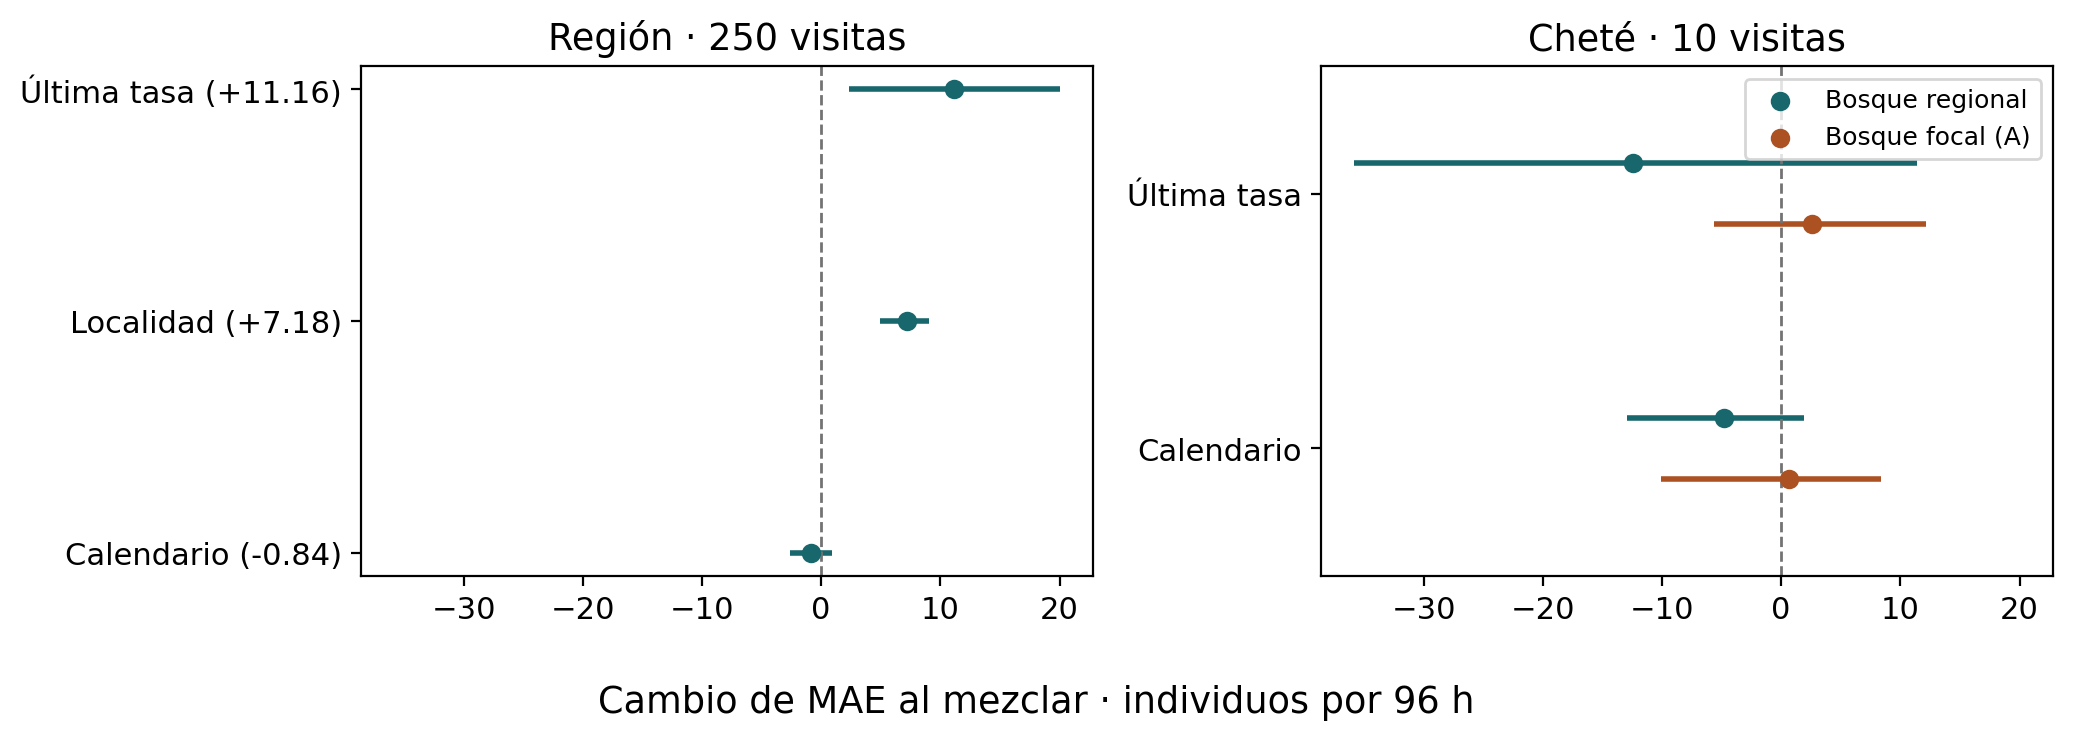

In [26]:
figImportancia, ejes = plt.subplots(1, 2, figsize=(10.5, 3.7), sharex=True)

def dibujarImportancia(ax, resultados, posiciones, color, etiqueta):
    ax.hlines(posiciones, resultados.P10, resultados.P90, color=color, linewidth=2)
    ax.scatter(resultados.Cambio, posiciones, color=color, label=etiqueta, zorder=3)


ax = ejes[0]
y = np.arange(len(impRegional))
dibujarImportancia(ax, impRegional, y, "#17676d", bosqueRegional)
ax.set_yticks(y, [f"{r.Variable} ({r.Cambio:+.2f})" for r in impRegional.itertuples()])
ax.set_title(f"Región · {sum(len(x) for _, x, _ in casosRegion)} visitas")
ax.invert_yaxis()
ax = ejes[1]
y = np.arange(len(gruposTemporales))
for nombre, ajuste, color in [(bosqueRegional, -.12, "#17676d"), (bosqueFocal, .12, "#ac5222")]:
    dibujarImportancia(ax, impChete[nombre], y + ajuste, color, nombre)
ax.set_yticks(y, list(gruposTemporales))
ax.set_title(f"Cheté · {len(casosChete[bosqueFocal])} visitas")
ax.set_ylim(1.5, -.5)
ax.legend(loc="upper right", fontsize=9)
for ax in ejes:
    ax.axvline(0, color=".45", linestyle="--", linewidth=1)
figImportancia.supxlabel("Cambio de MAE al mezclar · individuos por 96 h")
figImportancia.tight_layout()
plt.show()

En la región, mezclar la última tasa aumentó el MAE en **+11,16** y mezclar la
localidad en **+7,18**; el calendario registró **−0,84**. En Cheté, los rangos
de calendario y última tasa cruzan cero para ambos bosques: no se distingue un
predictor ganador en esas diez visitas.

**La etiqueta no es una exposición.** Municipio–localidad no mide CO₂ ambiental,
cercanía a una mina ni interior/exterior. El ZIP tampoco trae mediciones por
evento de color del recipiente, señuelo o lluvia, ni hay conteos separados para
interior y exterior. No se puede estimar su importancia; eso no equivale a un
efecto nulo. La permutación tampoco identifica causas.

## 8. ¿Podemos ordenar los meses de Cheté?

Como diagnóstico retrospectivo, desde abril de 2022 pronosticamos de una vez
los meses observados durante los siguientes doce meses, sin actualizar la última
tasa. En los pares de meses con cantidades observadas distintas (redondeadas al
individuo por 96 h), acertar el orden vale 1 y predecir un empate vale ½.
Los pares comparten visitas; no son ensayos independientes.

In [27]:
# Solo después de evaluar el bloque incorporamos todos los sitios y meses del ZIP.
regional = leerFilas(set(calendario.index))
eventosRegional = reconstruirEventos(regional)
campanasRegional = formarCampanas(eventosRegional)
cheteCompleto = campanasRegional.loc[campanasRegional.sitio.eq(localidadObjetivo)]
assert len(cheteCompleto) == len(visitas) + len(prueba)
assert np.allclose(cheteCompleto.tasa.tail(len(prueba)), prueba.tasa)

corteOrden = pd.Timestamp("2022-04-01")
finOrden = corteOrden + pd.DateOffset(years=1)
historiaOrden = campanasRegional.loc[campanasRegional.fin.lt(corteOrden)]
objetivosOrden = cheteCompleto.loc[cheteCompleto.fecha.ge(corteOrden) & cheteCompleto.fecha.lt(finOrden)]
ajustesOrden, _ = ajustarBosques(historiaOrden, corteOrden)
predOrden, _ = pronosticar(ajustesOrden, historiaOrden, objetivosOrden)
i, j = np.triu_indices(len(objetivosOrden), k=1)

def ordenEntrePares(cantidades):
    enteros = np.rint(np.asarray(cantidades, dtype=float))
    return np.sign(enteros[j] - enteros[i])

ordenReal = ordenEntrePares(esfuerzoObjetivo * objetivosOrden.tasa)
compara = ordenReal != 0
print(f"{compara.sum()} pares con cantidades distintas, de {len(objetivosOrden)} meses observados.")
aciertosOrden = {}
for nombre in [*nombresBosques, nombreHistorica]:
    ordenPred = ordenEntrePares(predOrden[nombre])[compara]
    aciertos = np.where(ordenPred == 0, .5, ordenPred == ordenReal[compara])
    aciertosOrden[nombre] = 100 * aciertos.mean()
    print(f"{nombre}: {aciertosOrden[nombre]:.1f} % de acierto en el orden.")

45 pares con cantidades distintas, de 10 meses observados.
Bosque regional: 41.1 % de acierto en el orden.
Bosque focal (A): 60.0 % de acierto en el orden.
Tasa histórica: 50.0 % de acierto en el orden.


Este contraste de un solo año no demuestra un orden mensual estable, y un
ranking regional no se puede trasladar a Cheté.

### Cantidad de referencia y próximos meses

Para planificar, actualizamos la tasa histórica con las 22 visitas disponibles al
cierre de marzo de 2023, sin cambiar los resultados de la evaluación anterior.
La referencia es constante por construcción; no indica qué mes conviene más.

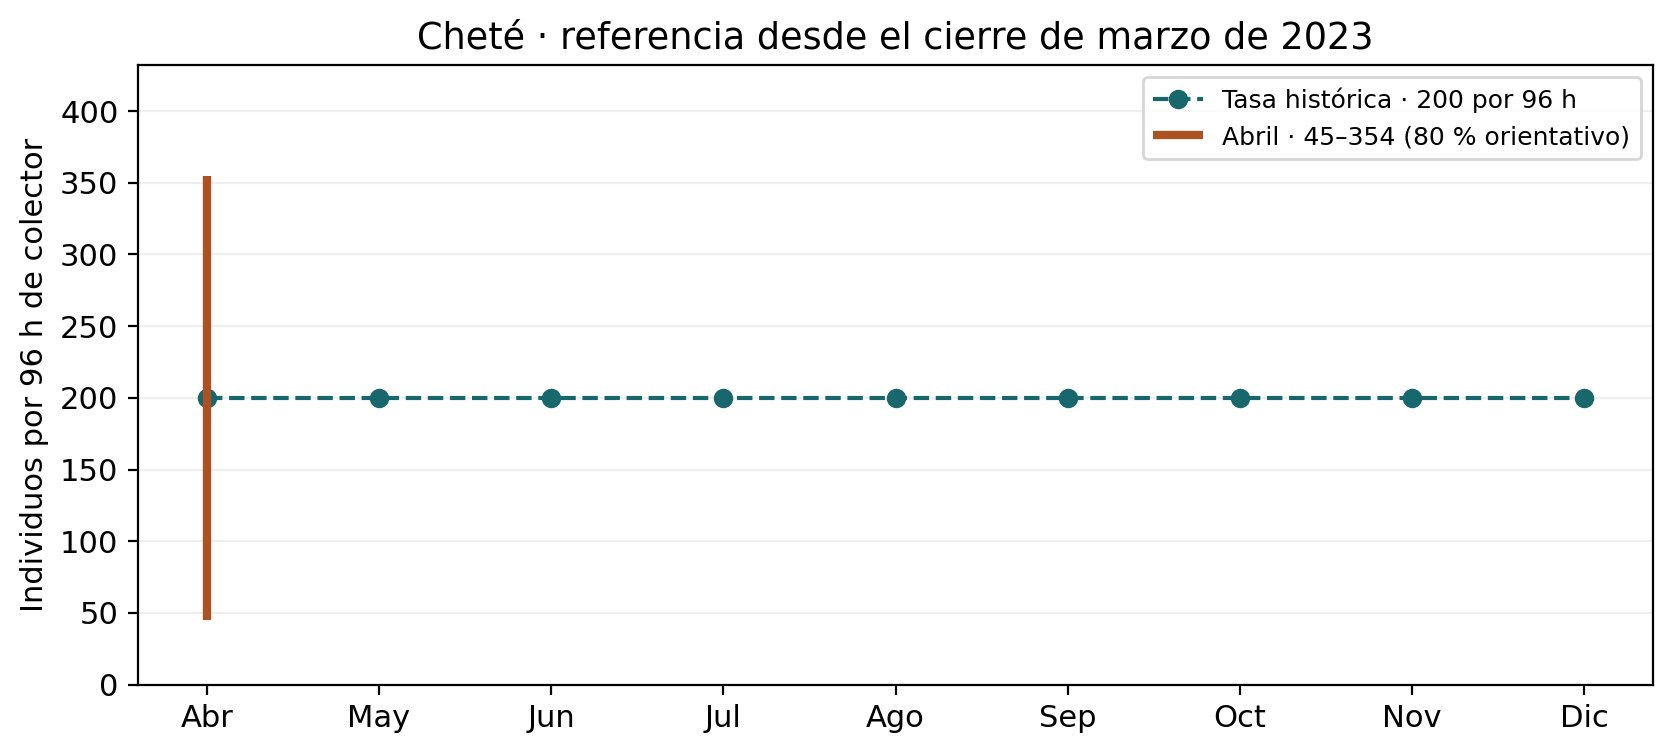

In [28]:
cortePronostico = pd.Timestamp("2023-04-01")
assert cheteCompleto.fin.lt(cortePronostico).all()
assert recomendado == nombreHistorica  # La regla de comparación conserva esta referencia en el ZIP.
prevision = esfuerzoObjetivo * tasaConjunta(cheteCompleto)
margenAbril = margenesHorizonte[1][nombreHistorica]
abrilBajo, abrilAlto = max(0, prevision - margenAbril), prevision + margenAbril
modeloCharla = {
    "ult_mae": float(mae2023[nombreUltima]),
    "hist_mae": float(mae2023[nombreHistorica]),
    "rfreg_mae": float(mae2023[bosqueRegional]),
    "rflocal_mae": float(mae2023[bosqueFocal]),
    "prevision": float(prevision),
    "abril_bajo": float(abrilBajo),
    "abril_alto": float(abrilAlto),
}

meses = ["Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
figPronostico, ax = plt.subplots(figsize=(8.5, 3.9))
ax.plot(meses, [prevision] * len(meses), "o--", color="#17676d",
        label=f"Tasa histórica · {prevision:.0f} por 96 h")
ax.vlines(0, abrilBajo, abrilAlto, color="#ac5222", linewidth=3,
          label=f"Abril · {abrilBajo:.0f}–{abrilAlto:.0f} (80 % orientativo)")
ax.set(ylabel="Individuos por 96 h de colector", ylim=(0, abrilAlto * 1.22),
       title="Cheté · referencia desde el cierre de marzo de 2023")
ax.legend(loc="upper right", fontsize=9)
ax.grid(axis="y", alpha=.2)
figPronostico.tight_layout()
plt.show()

Abril tiene un margen orientativo al adelanto de un mes. Los otros ocho meses se
muestran **sin banda**: no extrapolamos ese margen. Noviembre queda a ocho meses
y diciembre a nueve, fuera de los adelantos calibrados.

Mantendríamos noviembre para repetir nuestra comparación; diciembre sigue siendo parte de la hipótesis inicial. Usaríamos
observaciones comparables, sin interpretar el pronóstico como un máximo. Los
**200** de la referencia son para **cuatro noches completas (96 horas de
colector)**; los **200** de la Fermi eran **por recipiente y por noche**.

**Qué aportó el cierre de Poisson.** Comparamos sus predicciones congeladas con la misma reserva que la última visita y la Fermi revisada. Un bosque propuesto después no convierte esta reserva en una segunda prueba ciega. Con tres visitas, cubrir las tres no garantiza cobertura futura.

In [29]:
prediccionesPoisson = referencias(visitas, len(prueba))
prediccionesPoisson["Poisson"] = pronosticoCerrado
for nombre, pred in prediccionesPoisson.items():
    observado = prueba.cuatroNoches.to_numpy(dtype=float)
    error = pred - observado
    bajo, alto = np.maximum(0, pred - margenes[nombre]), pred + margenes[nombre]
    dentro = (bajo <= observado) & (observado <= alto)
    print(f"{nombre}: MAE {abs(error).mean():.2f} · RMSE {np.sqrt((error**2).mean()):.2f} · "
          f"cobertura {dentro.sum()}/{len(dentro)} · ancho medio {(alto-bajo).mean():.0f} ind./96 h")
print(f"La reserva contenía {int(pruebaPreparada.fechaRecuperada.sum())} fila con fecha recuperable; "
      "los registros con identificadores distintos se conservan aunque compartan evento y especie.")

Última visita: MAE 44.83 · RMSE 54.11 · cobertura 3/3 · ancho medio 326 ind./96 h
Fermi revisada: MAE 64.04 · RMSE 80.74 · cobertura 3/3 · ancho medio 310 ind./96 h
Poisson: MAE 68.08 · RMSE 84.76 · cobertura 3/3 · ancho medio 299 ind./96 h
La reserva contenía 1 fila con fecha recuperable; los registros con identificadores distintos se conservan aunque compartan evento y especie.


## Del sitio al estudio completo: mismo esfuerzo, otra escala

Terminada la evaluación, comprobamos los totales del ZIP contra la publicación del INS. Todo el ZIP incluye a Cheté y mezcla meses; no es el panel de localidades externas comparables. Para ver cuánto depende la respuesta de nuestro reparto de noches, repetimos el resumen local dando el mismo peso a los dos puntos y luego también a los años. No los rebautizamos «mina» y «población».

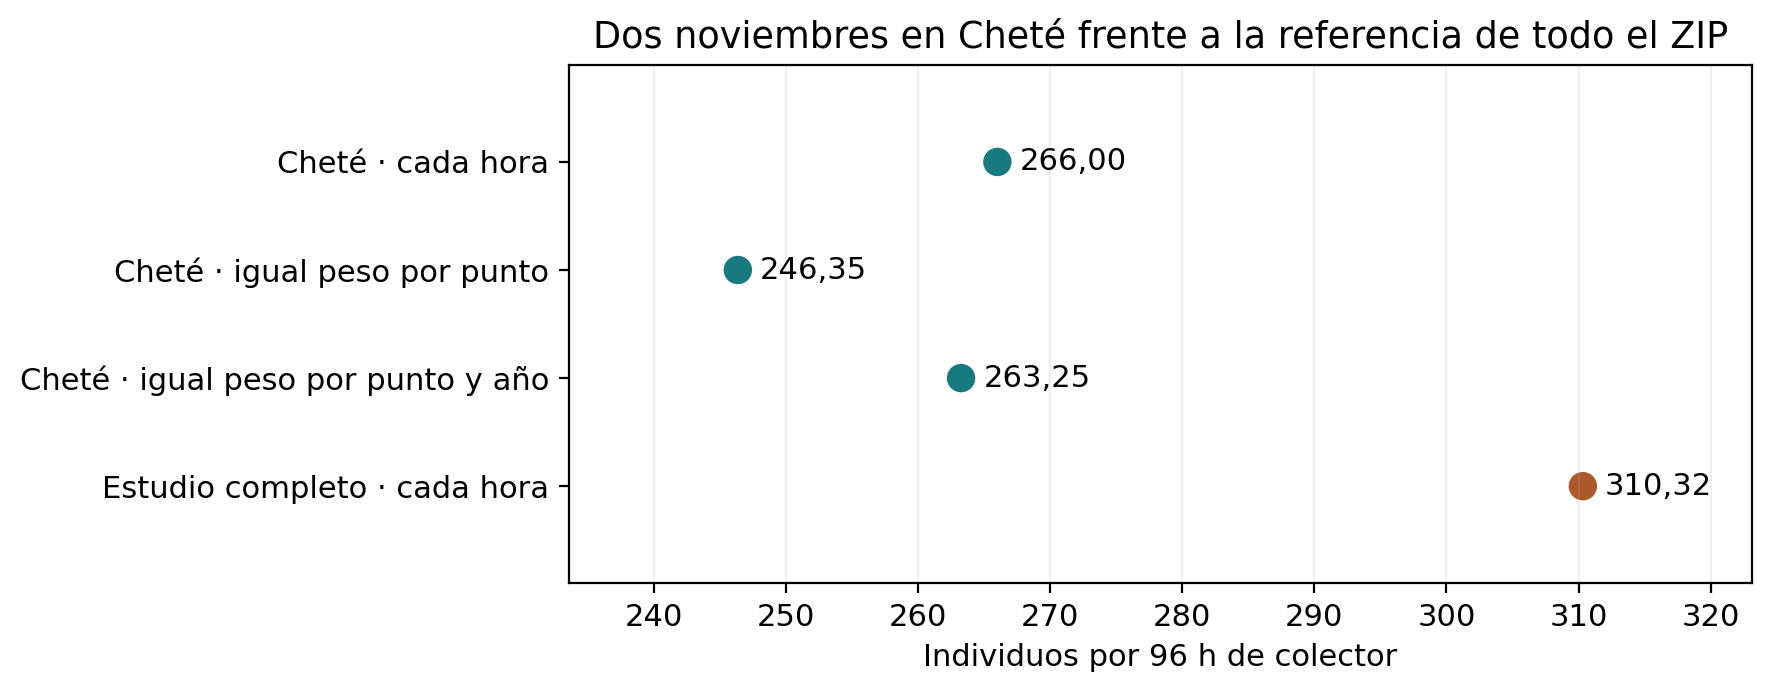

In [30]:
def equivalente(tabla):
    return esfuerzoObjetivo * tasaConjunta(tabla)

# Primero sumamos individuos y horas; recién después sacamos la tasa.
porPunto = puntosNoviembre.groupby("parentEventID")[["conteo", "esfuerzo"]].sum()
porPuntoAnio = puntosNoviembre.groupby(["parentEventID", "fecha"])[["conteo", "esfuerzo"]].sum()
valores96 = {
    "Cheté · cada hora": equivalente(puntosNoviembre),
    "Cheté · igual peso por punto": esfuerzoObjetivo * (porPunto.conteo / porPunto.esfuerzo).mean(),
    "Cheté · igual peso por punto y año": esfuerzoObjetivo * (porPuntoAnio.conteo / porPuntoAnio.esfuerzo).mean(),
    "Estudio completo · cada hora": equivalente(eventosRegional),
}
assert eventosRegional.conteo.sum() == individuosResumen and len(regional) == registrosResumen
assert regional.sex.eq("Hembra").all() and regional.lifeStage.eq("Adulto").all()
fig, ax = plt.subplots(figsize=(9, 3.6))
pos = np.arange(len(valores96))
ax.scatter(list(valores96.values()), pos, c=["#167a80"]*3 + ["#ad5828"], s=85)
for y, valor in zip(pos, valores96.values()):
    ax.annotate(f"{valor:.2f}".replace(".", ","), (valor, y), xytext=(8, 0), textcoords="offset points", va="center")
ax.set(yticks=pos, yticklabels=list(valores96), xlabel="Individuos por 96 h de colector",
       title="Dos noviembres en Cheté frente a la referencia de todo el ZIP")
ax.margins(x=.20, y=.3)
ax.invert_yaxis()
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
plt.show()

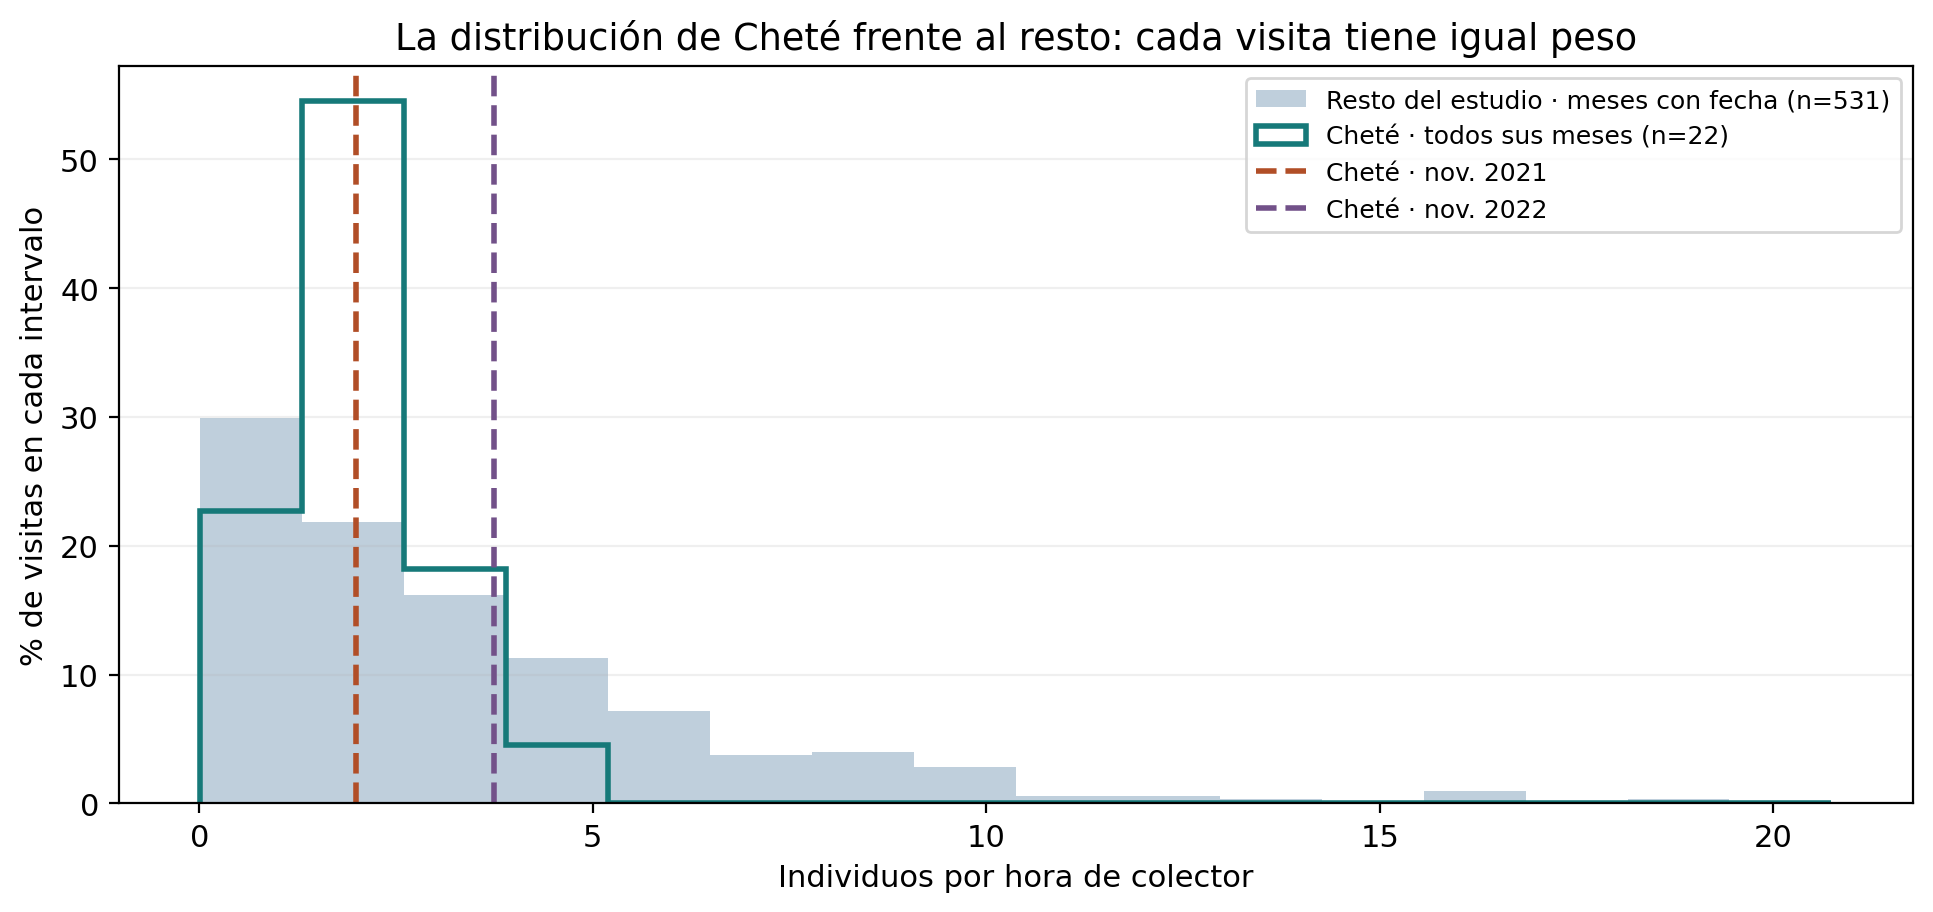

In [31]:
figHistograma, ax = plt.subplots(figsize=(9.8, 4.7))
restoCampanas = campanasRegional.loc[campanasRegional.sitio.ne(localidadObjetivo)]
bordes = np.histogram_bin_edges(campanasRegional.tasa.to_numpy(dtype=float), bins=16)
for tabla, color, estilo, nombre in [
    (restoCampanas, "#49789c", "stepfilled", "Resto del estudio · meses con fecha"),
    (cheteCompleto, "#167979", "step", "Cheté · todos sus meses"),
]:
    tasas = tabla.tasa.to_numpy(dtype=float)
    ax.hist(tasas, bins=bordes, histtype=estilo, linewidth=2,
            weights=np.full(len(tasas), 100 / len(tasas)), color=color,
            alpha=.35 if estilo == "stepfilled" else 1, label=f"{nombre} (n={len(tasas)})")
for fila, color in zip(visitasNoviembre.itertuples(), ["#b14e27", "#725189"]):
    ax.axvline(fila.tasa, color=color, lw=2, ls="--", label=f"Cheté · nov. {fila.fecha.year}")
ax.set(xlabel="Individuos por hora de colector", ylabel="% de visitas en cada intervalo",
       title="La distribución de Cheté frente al resto: cada visita tiene igual peso")
ax.grid(axis="y", alpha=.2)
ax.legend(loc="upper right", fontsize=9)
figHistograma.tight_layout()
plt.show()

**Cómo leer los mapas.** Solo se dibujan eventos con una posición WGS84 inequívoca. Los que faltan o se contradicen siguen contando en los totales, no en el mapa. El color indica captura por hora, no exposición minera ni riesgo de malaria. El resumen del INS declara 25 localidades; el ZIP distingue 27 etiquetas municipio–localidad. No fusionamos nombres sin una equivalencia documentada.

In [32]:
camposXY = ["decimalLongitude", "decimalLatitude"]
xy = regional[claveEvento + camposXY + ["geodeticDatum"]].copy()
xy[camposXY] = xy[camposXY].apply(pd.to_numeric, errors="coerce")
validas = xy.geodeticDatum.eq("WGS84") & xy.decimalLongitude.between(-180, 180) & xy.decimalLatitude.between(-90, 90)
catalogo = xy.loc[validas, claveEvento + camposXY].drop_duplicates()
# Conservar todas las ocurrencias al contar, pero una sola posición por evento al dibujar.
unicas = catalogo.loc[~catalogo.duplicated(claveEvento, keep=False)]
eventosUbicados = eventosRegional.merge(unicas, on=claveEvento, validate="one_to_one")
mapaRegional = eventosUbicados.groupby(camposXY, as_index=False)[["conteo", "esfuerzo"]].sum()
mapaRegional["tasa"] = mapaRegional.conteo / mapaRegional.esfuerzo
coberturaMapa = eventosUbicados.conteo.sum() / eventosRegional.conteo.sum()
print(f"El mapa conserva {len(mapaRegional)} posiciones y {coberturaMapa:.1%} de los individuos.")

El mapa conserva 40 posiciones y 92.8% de los individuos.


In [33]:
archivoLimites = datos / "limites_pacifico.geojson"
with archivoLimites.open(encoding="utf-8") as fuenteMapa:
    limites = json.load(fuenteMapa)["features"]
colombia = next(f["geometry"] for f in limites if f["properties"]["nivel"] == "pais")
municipios = {
    f["properties"]["nombre"]: f["geometry"]
    for f in limites if f["properties"]["nivel"] == "municipio"
}

def anillosPorPoligono(geometria):
    if geometria["type"] == "Polygon":
        return [geometria["coordinates"]]
    assert geometria["type"] == "MultiPolygon"
    return geometria["coordinates"]

def enPoligonos(posiciones, geometria):
    """Dentro del contorno exterior y fuera de los huecos."""
    dentro = np.zeros(len(posiciones), dtype=bool)
    for exterior, *huecos in anillosPorPoligono(geometria):
        enExterior = Trayectoria(exterior).contains_points(posiciones)
        for hueco in huecos:
            enExterior &= ~Trayectoria(hueco).contains_points(posiciones)
        dentro |= enExterior
    return dentro

def pintarPoligonos(eje, geometria, relleno, borde, grosor=.7):
    for anillos in anillosPorPoligono(geometria):
        trazados = [Trayectoria(anillo, closed=True) for anillo in anillos]
        eje.add_patch(PathPatch(Trayectoria.make_compound_path(*trazados), facecolor=relleno,
                                edgecolor=borde, linewidth=grosor, zorder=0))

chequeoMunicipio = eventosUbicados[["county", *camposXY]].drop_duplicates()
coinciden = pd.Series(False, index=chequeoMunicipio.index)
for nombre, grupo in chequeoMunicipio.groupby("county"):
    coinciden.loc[grupo.index] = enPoligonos(
        grupo[camposXY].to_numpy(dtype=float), municipios[nombre.upper()]
    )
print(f"Coordenadas dentro del municipio publicado: {coinciden.sum()} de {len(coinciden)}.")
assert coinciden.all()

Coordenadas dentro del municipio publicado: 40 de 40.


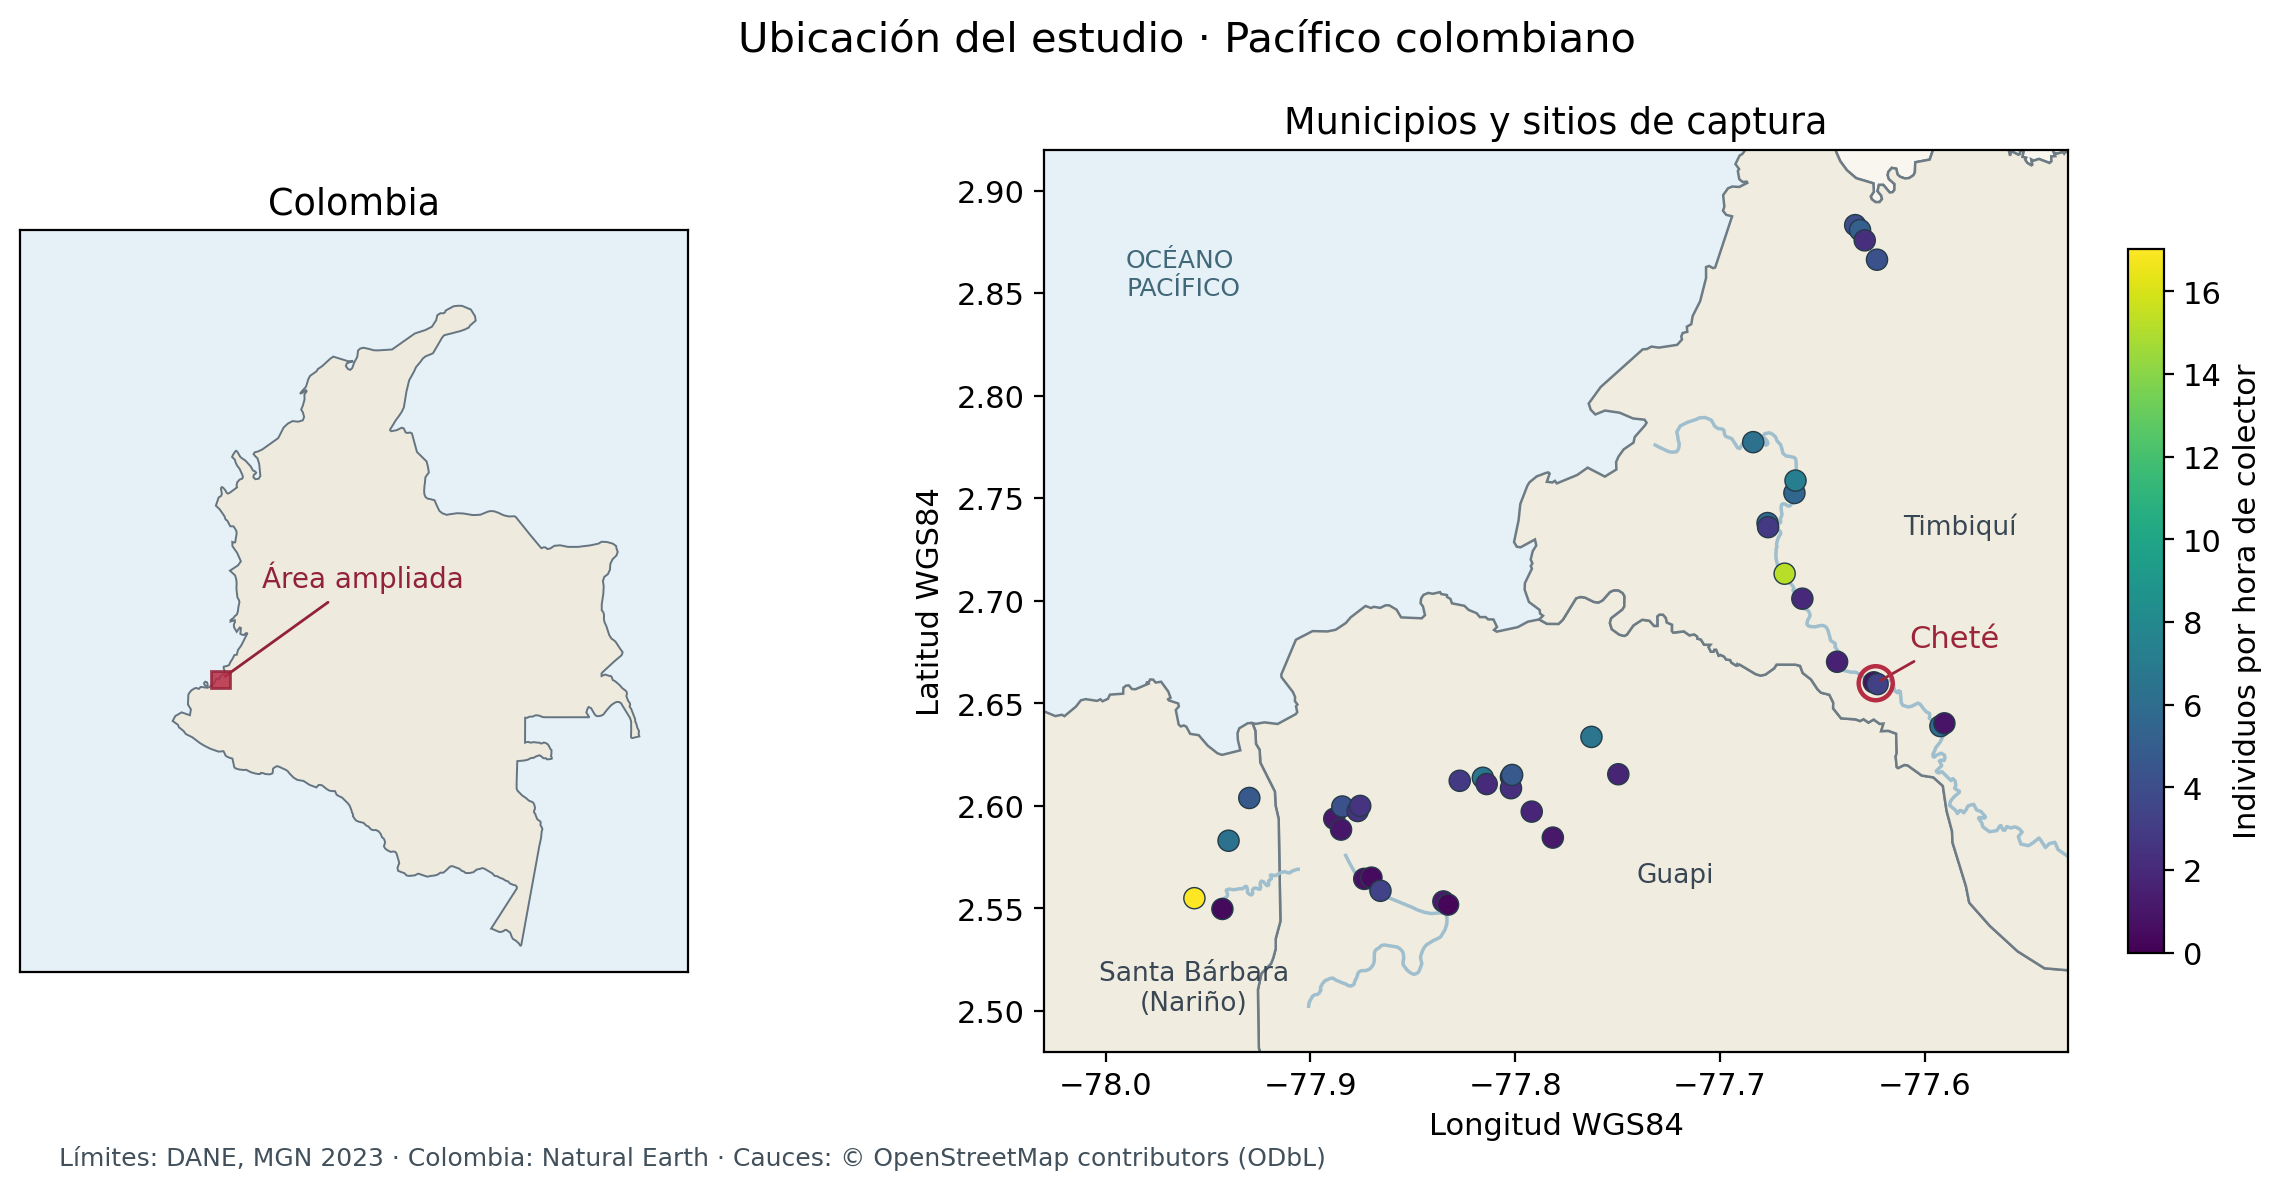

In [34]:
encuadre = (-78.03, -77.53, 2.48, 2.92)
figMapaRegional, (axPais, ax) = plt.subplots(
    1, 2, figsize=(12, 6.1), gridspec_kw={"width_ratios": [1, 2.25]}
)
pintarPoligonos(axPais, colombia, "#eeeadd", "#647480")
x0, x1, y0, y1 = encuadre
axPais.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc="#b62c43",
                           ec="#92213a", alpha=.85, zorder=4))
axPais.annotate("Área ampliada", ((x0 + x1) / 2, (y0 + y1) / 2),
                xytext=(-76.7, 5.1), color="#92213a", fontsize=10,
                arrowprops={"arrowstyle": "-", "color": "#92213a"})
axPais.set(xlim=(-83, -65.6), ylim=(-4.9, 14.4), aspect="equal", title="Colombia")
axPais.set_xticks([])
axPais.set_yticks([])
axPais.set_facecolor("#e6f0f7")

dibujarCauces(ax)
ax.set_facecolor("#e6f0f7")
for nombre, geometria in municipios.items():
    fondo = "#f0ecdf" if nombre in {"TIMBIQUÍ", "GUAPI", "SANTA BÁRBARA"} else "#f8f6ef"
    pintarPoligonos(ax, geometria, fondo, "#6d7b85", .9)
ax.text(-77.99, 2.872, "OCÉANO\nPACÍFICO", color="#406879", fontsize=9, va="top")
for textoMapa, x, y in [
    ("Timbiquí", -77.555, 2.736), ("Guapi", -77.722, 2.566),
    ("Santa Bárbara\n(Nariño)", -77.957, 2.511)
]:
    ax.text(x, y, textoMapa, ha="right" if textoMapa == "Timbiquí" else "center",
            va="center", color="#394653", fontsize=9.5, zorder=2)

puntosMapa = ax.scatter(mapaRegional.decimalLongitude, mapaRegional.decimalLatitude,
                        c=mapaRegional.tasa, cmap="viridis", vmin=0, s=58,
                        edgecolors="#253b48", linewidths=.5, zorder=3)
xyChete = eventosUbicados.loc[(eventosUbicados.county == "Timbiquí") & (eventosUbicados.locality == "Cheté"), camposXY]
cx, cy = xyChete.drop_duplicates().mean()
ax.scatter(cx, cy, marker="o", s=150, facecolors="none", edgecolors="#b62c43",
           lw=1.6, zorder=4)
ax.annotate("Cheté", (cx, cy), xytext=(12, 13), textcoords="offset points",
            color="#9d253a", arrowprops={"arrowstyle": "-", "color": "#9d253a"})
ax.set(xlim=(x0, x1), ylim=(y0, y1), title="Municipios y sitios de captura", xlabel="Longitud WGS84", ylabel="Latitud WGS84")
ax.set_aspect(1 / np.cos(np.radians(cy)))
figMapaRegional.suptitle("Ubicación del estudio · Pacífico colombiano", fontsize=15, y=.96)
figMapaRegional.colorbar(puntosMapa, ax=ax, shrink=.78, pad=.04, label="Individuos por hora de colector")
figMapaRegional.text(.03, .021,
                     "Límites: DANE, MGN 2023 · Colombia: Natural Earth · Cauces: © OpenStreetMap contributors (ODbL)",
                     fontsize=9, color="#41505b")
figMapaRegional.tight_layout(rect=(0, .055, 1, .94))
plt.show()

## Qué decisión cambió

**Mantendríamos noviembre por comparabilidad**, no como máximo demostrado. La ubicación dejó una señal tanto en Cheté como en parte de la región; los sectores de nuestra propuesta no son una exposición identificada en el ZIP. De las variables de nuestra hoja que el estudio no midió, **priorizamos el CO₂ ambiental del lugar con hora de lectura**. Una lectura puntual no representa toda la noche ni identifica el origen del gas. La lluvia fechada respondería otra pregunta: verificar la temporada. Y solo observaciones de los propios recipientes permitirían evaluar su rendimiento.

**Para probar durante la charla.** Al dividir `qEscenario` por dos se divide solo la cuenta de frascos, no los conteos del INS. Al ponderar igual los dos puntos cambia la tasa de noviembre, no los individuos observados. Al aumentar el mínimo de meses compartidos pueden cambiar los pares elegibles, no las visitas de la reserva. Son tres cambios distintos: de supuesto, de ponderación y de muestra.

La IA ayudó a contrastar unidades, separar el calendario de la reserva y comprobar las figuras. La explicación de las decisiones, los aportes y la reflexión personal corresponden a cada integrante.

**Fuentes.** [INS v1.0, DOI 10.15472/kftrcn](https://doi.org/10.15472/kftrcn) · [CDC: ciclo de *Anopheles*](https://www.cdc.gov/mosquitoes/about/life-cycle-of-anopheles-mosquitoes.html) · [Ellwanger y colaboradores, antecedente sobre señales humanas](https://pubmed.ncbi.nlm.nih.gov/35284885/) · [DANE MGN 2023](https://geoportal.dane.gov.co/descargas/mgn_2023/MGN2023_CatalogoDeObjetos.pdf) · [Natural Earth](https://www.naturalearthdata.com/about/terms-of-use/) · [OpenStreetMap](https://www.openstreetmap.org/copyright). Datos INS: CC BY-NC 4.0. La [presentación](Presentacion.pdf) se prepara por separado con las figuras de este notebook.

In [35]:
# Resumen legible por la presentación: una sola fuente para las cifras, sin generar el PDF aquí.
datosCharla = {
    "fermi": fermiOriginal, "margen": margenOriginal, "producto": fermiProducto,
    "regional_fermi": fermiExtendida, "regional_ins": individuosResumen, "desvio_pct": abs(porcentajeFermi),
    "nov_cuenta": int(puntosNoviembre.conteo.sum()), "nov_h": int(puntosNoviembre.esfuerzo.sum()),
    "escenario8": float(escenarioNoviembre[0]), "escenario10": float(escenarioNoviembre[1]), "q": qEscenario,
    "visitas": len(visitas), "gana1": int((diferencias > 0).sum()), "efecto": float(mediaDif),
    "ic_bajo": float(icBajo), "ic_alto": float(icAlto), "tasas96": [equivalente(puntosNoviembre), equivalente(eventosRegional)],
    **modeloCharla,
    "pesos": list(valores96.values()), "contrastes": resumenContrastes, "firma_poisson": firmaModelo,
}
display(JSON(datosCharla, expanded=False))

<IPython.core.display.JSON object>